In [ ]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization (later use)
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Preprocessing (will be used later)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# Utility
import os
import warnings
warnings.filterwarnings("ignore")

# Load All Files

In [ ]:
# Install (if not already)
!pip install -q kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter

# =========================
# EXPEDITION DATASET
# =========================

print("===== EXPEDITION DATASET FILES =====")

expedition_files = kagglehub.dataset_download("siddharth0935/himalayan-expeditions")
print("Download path:", expedition_files)

import os

for root, dirs, files in os.walk(expedition_files):
    print("\n📁", root)
    for f in files:
        print("   📄", f)


# =========================
# WEATHER DATASET
# =========================

print("\n\n===== WEATHER DATASET FILES =====")

weather_files = kagglehub.dataset_download("bonesclarke26/historic-weather-data-for-himalayan-peaks")
print("Download path:", weather_files)

for root, dirs, files in os.walk(weather_files):
    print("\n📁", root)
    for f in files:
        print("   📄", f)

===== EXPEDITION DATASET FILES =====
Using Colab cache for faster access to the 'himalayan-expeditions' dataset.
Download path: /kaggle/input/himalayan-expeditions

📁 /kaggle/input/himalayan-expeditions
   📄 refer.csv
   📄 himalayan_data_dictionary.csv
   📄 peaks.csv
   📄 members.csv
   📄 exped.csv


===== WEATHER DATASET FILES =====
Using Colab cache for faster access to the 'historic-weather-data-for-himalayan-peaks' dataset.
Download path: /kaggle/input/historic-weather-data-for-himalayan-peaks

📁 /kaggle/input/historic-weather-data-for-himalayan-peaks
   📄 LHOT.txt
   📄 EVER.parquet
   📄 MANA.txt
   📄 ANN1.txt
   📄 TUKU.txt
   📄 CHOY.txt
   📄 HIML.txt
   📄 PUMO.parquet
   📄 ANNS.parquet
   📄 PUTH.txt
   📄 ANNS.txt
   📄 MAKA.txt
   📄 BARU.parquet
   📄 JANU.parquet
   📄 ANN4.txt
   📄 PUTH.parquet
   📄 JANU.txt
   📄 BARU.txt
   📄 ANN3.parquet
   📄 KANG.parquet
   📄 ANN1.parquet
   📄 CHOY.parquet
   📄 TILI.txt
   📄 AMAD.txt
   📄 LSHR.txt
   📄 AMAD.parquet
   📄 TUKU.parquet
   📄 ANN2.pa

In [ ]:
# =========================
# STEP 1: Define Paths
# =========================

expedition_path = "/kaggle/input/himalayan-expeditions"
weather_path = "/kaggle/input/historic-weather-data-for-himalayan-peaks"


# =========================
# STEP 2: Load Expedition Data (UNCHANGED LOGIC)
# =========================

import pandas as pd

expeditions = pd.read_csv(f"{expedition_path}/exped.csv")
peaks = pd.read_csv(f"{expedition_path}/peaks.csv")
members = pd.read_csv(f"{expedition_path}/members.csv")  # optional

print(expeditions.head())
print(peaks.head())


# =========================
# STEP 3: Load Weather Data (MATCH YOUR STRUCTURE)
# =========================

import glob
import os

weather_files = glob.glob(f"{weather_path}/*.parquet")

weather_by_peak = {}

for file in weather_files:
    peak_code = os.path.basename(file).replace(".parquet", "").upper()
    df = pd.read_parquet(file)
    df['date'] = pd.to_datetime(df['date']).dt.date
    weather_by_peak[peak_code] = df

print(weather_by_peak.keys())

       expid peakid  year  season   host            route1            route2  \
0  ANN260101   ANN2  1960  Spring  Nepal  NW Ridge-W Ridge               NaN   
1  ANN269301   ANN2  1969  Autumn  Nepal  NW Ridge-W Ridge               NaN   
2  ANN273101   ANN2  1973  Spring  Nepal    W Ridge-N Face               NaN   
3  ANN278301   ANN2  1978  Autumn  Nepal    N Face-W Ridge               NaN   
4  ANN279301   ANN2  1979  Autumn  Nepal    N Face-W Ridge  NW Ridge of A-IV   

  route3 route4      nation  ...                           accidents  \
0    NaN    NaN          UK  ...                                 NaN   
1    NaN    NaN  Yugoslavia  ...  Draslar frostbitten hands and feet   
2    NaN    NaN       Japan  ...                                 NaN   
3    NaN    NaN          UK  ...                                 NaN   
4    NaN    NaN          UK  ...                                 NaN   

  achievment  agency  comrte  stdrte  primrte primmem primref primid   chksum  
0     

In [ ]:
expeditions.columns

Index(['expid', 'peakid', 'year', 'season', 'host', 'route1', 'route2',
       'route3', 'route4', 'nation', 'leaders', 'sponsor', 'success1',
       'success2', 'success3', 'success4', 'ascent1', 'ascent2', 'ascent3',
       'ascent4', 'claimed', 'disputed', 'countries', 'approach', 'bcdate',
       'smtdate', 'smttime', 'smtdays', 'totdays', 'termdate', 'termreason',
       'termnote', 'highpoint', 'traverse', 'ski', 'parapente', 'camps',
       'rope', 'totmembers', 'smtmembers', 'mdeaths', 'tothired', 'smthired',
       'hdeaths', 'nohired', 'o2used', 'o2none', 'o2climb', 'o2descent',
       'o2sleep', 'o2medical', 'o2taken', 'o2unkwn', 'othersmts', 'campsites',
       'accidents', 'achievment', 'agency', 'comrte', 'stdrte', 'primrte',
       'primmem', 'primref', 'primid', 'chksum'],
      dtype='object')

In [ ]:
date_cols = ['bcdate', 'smtdate', 'termdate']

for col in date_cols:
    expeditions[col] = pd.to_datetime(expeditions[col], errors='coerce').dt.date

expeditions[date_cols].head()

,bcdate,smtdate,termdate
0,1960-03-15,1960-05-17,NaT
1,1969-09-25,1969-10-22,1969-10-26
2,1973-03-16,1973-05-06,NaT
3,1978-09-08,1978-10-02,1978-10-05
4,NaT,1979-10-18,1979-10-20


In [ ]:
peaks.columns

Index(['peakid', 'pkname', 'pkname2', 'location', 'heightm', 'heightf',
       'himal', 'region', 'open', 'unlisted', 'trekking', 'trekyear',
       'restrict', 'phost', 'pstatus', 'pyear', 'pseason', 'pmonth', 'pday',
       'pexpid', 'pcountry', 'psummiters', 'psmtnote'],
      dtype='object')

In [ ]:
peaks[['peakid','pkname','pkname2']].head(50)

,peakid,pkname,pkname2
0,ACHN,Aichyn,"Aychin, Ashvin"
1,AMAD,Ama Dablam,Amai Dablang
2,AMOT,Amotsang,Amatson
3,AMPG,Amphu Gyabjen,Amphu Gyabien
4,AMPH,Amphu I,NaN
5,AMPM,Amphu Middle,Amphu North
6,ANID,Anidesh Chuli,White Wave Peak
7,ANN1,Annapurna I,NaN
8,ANN2,Annapurna II,NaN
9,ANN3,Annapurna III,NaN


# Peak Mapping

In [ ]:
# Extract peak codes from weather files
weather_peak_codes = list(weather_by_peak.keys())

# Create mapping: weather peak code → itself (if exists in peaks.csv)
weather_to_peakid = {}

for code in weather_peak_codes:
    if code in set(peaks['peakid']):
        weather_to_peakid[code] = code
    else:
        weather_to_peakid[code] = None  # means weather exists but no expedition record

weather_to_peakid

{'EVER': 'EVER',
 'PUMO': 'PUMO',
 'ANNS': 'ANNS',
 'BARU': 'BARU',
 'JANU': 'JANU',
 'PUTH': 'PUTH',
 'ANN3': 'ANN3',
 'KANG': 'KANG',
 'ANN1': 'ANN1',
 'CHOY': 'CHOY',
 'AMAD': 'AMAD',
 'TUKU': 'TUKU',
 'ANN2': 'ANN2',
 'DHA1': 'DHA1',
 'MAK2': 'MAK2',
 'HIML': 'HIML',
 'LUNR': 'LUNR',
 'NUPT': 'NUPT',
 'GAUR': 'GAUR',
 'ANN4': 'ANN4',
 'LANG': 'LANG',
 'MANA': 'MANA',
 'MAKA': 'MAKA',
 'KGUR': 'KGUR',
 'LSHR': 'LSHR',
 'TILI': 'TILI',
 'LHOT': 'LHOT'}

# Validate Weather Peaks Present in Expeditions

In [ ]:
set(expeditions['peakid']).intersection(set(weather_peak_codes))

{'AMAD',
 'ANN1',
 'ANN2',
 'ANN3',
 'ANN4',
 'ANNS',
 'BARU',
 'CHOY',
 'DHA1',
 'EVER',
 'GAUR',
 'HIML',
 'JANU',
 'KANG',
 'KGUR',
 'LANG',
 'LHOT',
 'LSHR',
 'LUNR',
 'MAK2',
 'MAKA',
 'MANA',
 'NUPT',
 'PUMO',
 'PUTH',
 'TILI',
 'TUKU'}

# Filter Expeditions That Have Weather

In [ ]:
weather_peak_codes = set(weather_by_peak.keys())
expeditions_with_weather = expeditions[expeditions['peakid'].isin(weather_peak_codes)].copy()

len(expeditions_with_weather), len(expeditions)


(9457, 11425)

In [ ]:
from datetime import timedelta

def get_expedition_dates(row):
    start = row['bcdate']

    # Main end date
    end = row['termdate']

    # If missing, use summit day
    if pd.isna(end) and not pd.isna(row['smtdate']):
        end = row['smtdate']

    # If still missing, fallback to base camp + total days
    if pd.isna(end) and not pd.isna(start) and not pd.isna(row['totdays']):
        end = start + timedelta(days=int(row['totdays']))

    return start, end


# Add new columns
expeditions_with_weather['start_date'] = None
expeditions_with_weather['end_date'] = None

for idx, row in expeditions_with_weather.iterrows():
    s, e = get_expedition_dates(row)
    expeditions_with_weather.at[idx, 'start_date'] = s
    expeditions_with_weather.at[idx, 'end_date'] = e


In [ ]:
expeditions_with_weather[['peakid','bcdate','smtdate','termdate','start_date','end_date']].head()


,peakid,bcdate,smtdate,termdate,start_date,end_date
0,ANN2,1960-03-15,1960-05-17,NaT,1960-03-15,1960-05-17
1,ANN2,1969-09-25,1969-10-22,1969-10-26,1969-09-25,1969-10-26
2,ANN2,1973-03-16,1973-05-06,NaT,1973-03-16,1973-05-06
3,ANN2,1978-09-08,1978-10-02,1978-10-05,1978-09-08,1978-10-05
4,ANN2,NaT,1979-10-18,1979-10-20,NaT,1979-10-20


# Apply Extraction to All Expeditions (We will store slices in a list so we can summarize them in STEP 3.)

In [ ]:
# =========================
# FAST GROUPED WEATHER EXTRACTION (ORDER PRESERVED)
# =========================

weather_slices = [None] * len(expeditions_with_weather)  # preserve order

# Create index mapping (to restore original order)
index_positions = {idx: pos for pos, idx in enumerate(expeditions_with_weather.index)}

# Group by peakid
grouped = expeditions_with_weather.groupby('peakid')

for peak, group in grouped:
    weather_df = weather_by_peak.get(peak)

    # If no weather data for this peak → all None
    if weather_df is None:
        for idx in group.index:
            weather_slices[index_positions[idx]] = None
        continue

    # Process each expedition in this peak group
    for idx, row in group.iterrows():
        start_date = row['start_date']
        end_date = row['end_date']

        # Same logic as before
        if pd.isna(start_date) or pd.isna(end_date):
            slice_df = None
        else:
            mask = (weather_df['date'] >= start_date) & (weather_df['date'] <= end_date)
            slice_df = weather_df.loc[mask]
            if slice_df.empty:
                slice_df = None

        # Place in correct position
        weather_slices[index_positions[idx]] = slice_df


# Quick sanity check
print(f"Total slices: {len(weather_slices)}")
print(f"Non-empty slices: {sum([1 for x in weather_slices if x is not None])}")

Total slices: 9457
Non-empty slices: 8005


In [ ]:
expeditions_with_weather['weather_slice'] = weather_slices


In [ ]:
expeditions_with_weather[['peakid','start_date','end_date','weather_slice']].head(10)


,peakid,start_date,end_date,weather_slice
0,ANN2,1960-03-15,1960-05-17,None
1,ANN2,1969-09-25,1969-10-26,None
2,ANN2,1973-03-16,1973-05-06,None
3,ANN2,1978-09-08,1978-10-05,None
4,ANN2,NaT,1979-10-20,None
5,ANN2,1980-03-25,1980-05-01,peakid date temperature_2m relat...
6,ANN2,1980-04-09,1980-05-08,peakid date temperature_2m relat...
7,ANN2,1981-09-04,1981-09-23,peakid date temperature_2m rela...
8,ANN2,1981-09-04,1981-10-17,peakid date temperature_2m rela...
9,ANN2,1982-09-14,1982-10-08,peakid date temperature_2m rela...


In [ ]:
expeditions_with_weather.columns

Index(['expid', 'peakid', 'year', 'season', 'host', 'route1', 'route2',
       'route3', 'route4', 'nation', 'leaders', 'sponsor', 'success1',
       'success2', 'success3', 'success4', 'ascent1', 'ascent2', 'ascent3',
       'ascent4', 'claimed', 'disputed', 'countries', 'approach', 'bcdate',
       'smtdate', 'smttime', 'smtdays', 'totdays', 'termdate', 'termreason',
       'termnote', 'highpoint', 'traverse', 'ski', 'parapente', 'camps',
       'rope', 'totmembers', 'smtmembers', 'mdeaths', 'tothired', 'smthired',
       'hdeaths', 'nohired', 'o2used', 'o2none', 'o2climb', 'o2descent',
       'o2sleep', 'o2medical', 'o2taken', 'o2unkwn', 'othersmts', 'campsites',
       'accidents', 'achievment', 'agency', 'comrte', 'stdrte', 'primrte',
       'primmem', 'primref', 'primid', 'chksum', 'start_date', 'end_date',
       'weather_slice'],
      dtype='object')

In [ ]:
expeditions_with_weather.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9457 entries, 0 to 11422
Data columns (total 68 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   expid          9457 non-null   object 
 1   peakid         9457 non-null   object 
 2   year           9457 non-null   int64  
 3   season         9457 non-null   object 
 4   host           9457 non-null   object 
 5   route1         9422 non-null   object 
 6   route2         258 non-null    object 
 7   route3         15 non-null     object 
 8   route4         3 non-null      object 
 9   nation         9457 non-null   object 
 10  leaders        9444 non-null   object 
 11  sponsor        8946 non-null   object 
 12  success1       9457 non-null   bool   
 13  success2       9457 non-null   bool   
 14  success3       9457 non-null   bool   
 15  success4       9457 non-null   bool   
 16  ascent1        1975 non-null   object 
 17  ascent2        62 non-null     object 
 18  ascent3     

# STEP 3 — CLIMATE FEATURE EXTRACTION

In [ ]:
import numpy as np

def summarize_weather(df):
    if df is None or df.empty:
        return {
            'temp_mean': np.nan,
            'temp_max': np.nan,
            'temp_min': np.nan,
            'temp_std': np.nan,
            'snow_total': np.nan,
            'snow_max': np.nan,
            'heavy_snow_days': np.nan,
            'wind_mean': np.nan,
            'wind_max': np.nan,
            'extreme_wind_days': np.nan,
            'pressure_mean': np.nan,
            'pressure_min': np.nan,
            'rapid_warming_days': np.nan,
            'storm_days': np.nan
        }

    df = df.copy()

    # Compute day-to-day temperature change
    df['temp_change'] = df['temperature_2m'].diff()

    # Heavy snow
    heavy_snow = (df['snowfall'] > 10).sum()

    # Extreme wind
    extreme_wind = (df['wind_speed_100m'] > 70).sum()

    # Rapid warming (> 5°C in a day)
    rapid_warm = (df['temp_change'] > 5).sum()

    # Storm days from weather_code (codes >70 often storms)
    if 'weather_code' in df.columns:
        storm_days = (df['weather_code'] >= 70).sum()
    else:
        storm_days = np.nan

    return {
        'temp_mean': df['temperature_2m'].mean(),
        'temp_max': df['temperature_2m'].max(),
        'temp_min': df['temperature_2m'].min(),
        'temp_std': df['temperature_2m'].std(),

        'snow_total': df['snowfall'].sum(),
        'snow_max': df['snowfall'].max(),
        'heavy_snow_days': heavy_snow,

        'wind_mean': df['wind_speed_100m'].mean(),
        'wind_max': df['wind_speed_100m'].max(),
        'extreme_wind_days': extreme_wind,

        'pressure_mean': df['surface_pressure'].mean(),
        'pressure_min': df['surface_pressure'].min(),

        'rapid_warming_days': rapid_warm,
        'storm_days': storm_days
    }


In [ ]:
climate_features = []

for slice_df in expeditions_with_weather['weather_slice']:
    features = summarize_weather(slice_df)
    climate_features.append(features)

climate_df = pd.DataFrame(climate_features)
climate_df.head()

,temp_mean,temp_max,temp_min,temp_std,snow_total,snow_max,heavy_snow_days,wind_mean,wind_max,extreme_wind_days,pressure_mean,pressure_min,rapid_warming_days,storm_days
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
exped_full = pd.concat([expeditions_with_weather.reset_index(drop=True),
                        climate_df.reset_index(drop=True)], axis=1)

exped_full.head()

,expid,peakid,year,season,host,route1,route2,route3,route4,nation,...,snow_total,snow_max,heavy_snow_days,wind_mean,wind_max,extreme_wind_days,pressure_mean,pressure_min,rapid_warming_days,storm_days
0,ANN260101,ANN2,1960,Spring,Nepal,NW Ridge-W Ridge,NaN,NaN,NaN,UK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ANN269301,ANN2,1969,Autumn,Nepal,NW Ridge-W Ridge,NaN,NaN,NaN,Yugoslavia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ANN273101,ANN2,1973,Spring,Nepal,W Ridge-N Face,NaN,NaN,NaN,Japan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ANN278301,ANN2,1978,Autumn,Nepal,N Face-W Ridge,NaN,NaN,NaN,UK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ANN279301,ANN2,1979,Autumn,Nepal,N Face-W Ridge,NW Ridge of A-IV,NaN,NaN,UK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
exped_full.isnull().sum()

,0
expid,0
peakid,0
year,0
season,0
host,0
...,...
extreme_wind_days,1452
pressure_mean,1452
pressure_min,1452
rapid_warming_days,1452


In [ ]:
null_percent = exped_full.isna().mean() * 100
null_percent.sort_values(ascending=False)

,0
ascent4,99.978852
route4,99.968277
ascent3,99.947129
route3,99.841387
ascent2,99.344401
...,...
primmem,0.000000
stdrte,0.000000
comrte,0.000000
o2medical,0.000000


In [ ]:
missing_weather = exped_full['weather_slice'].isna().mean() * 100
print("Percentage of expeditions missing weather slices:", missing_weather)

Percentage of expeditions missing weather slices: 15.353706249339114


In [ ]:
climate_cols = [
    'temp_mean','temp_max','temp_min','temp_std',
    'snow_total','snow_max','heavy_snow_days',
    'wind_mean','wind_max','extreme_wind_days',
    'pressure_mean','pressure_min',
    'rapid_warming_days','storm_days'
]

rows_missing_any_climate = exped_full[climate_cols].isna().any(axis=1).mean() * 100
print("Percentage of expeditions with missing climate features:", rows_missing_any_climate)


Percentage of expeditions with missing climate features: 15.353706249339114


In [ ]:
exped_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9457 entries, 0 to 9456
Data columns (total 82 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   expid               9457 non-null   object 
 1   peakid              9457 non-null   object 
 2   year                9457 non-null   int64  
 3   season              9457 non-null   object 
 4   host                9457 non-null   object 
 5   route1              9422 non-null   object 
 6   route2              258 non-null    object 
 7   route3              15 non-null     object 
 8   route4              3 non-null      object 
 9   nation              9457 non-null   object 
 10  leaders             9444 non-null   object 
 11  sponsor             8946 non-null   object 
 12  success1            9457 non-null   bool   
 13  success2            9457 non-null   bool   
 14  success3            9457 non-null   bool   
 15  success4            9457 non-null   bool   
 16  ascent

# Vulnerability Feature Engineering

In [ ]:
exped_full['team_size'] = exped_full['totmembers']
exped_full['summit_rate'] = exped_full['smtmembers'] / exped_full['team_size'].replace(0, np.nan)
exped_full['death_rate'] = exped_full['mdeaths'] / exped_full['team_size'].replace(0, np.nan)

exped_full['oxygen_used'] = exped_full['o2used'].apply(lambda x: 1 if str(x).strip().upper() == 'Y' else 0)
exped_full['oxygen_free_ascent'] = exped_full['o2none'].apply(lambda x: 1 if str(x).strip().upper() == 'Y' else 0)

exped_full['exposure_days'] = exped_full['totdays']

exped_full['elevation_risk'] = exped_full['highpoint']

exped_full['camp_density'] = exped_full['camps'] / exped_full['totdays'].replace(0, np.nan)

exped_full['technical_difficulty'] = exped_full['rope'] / exped_full['totdays'].replace(0, np.nan)

exped_full['is_standard_route'] = exped_full['stdrte'].apply(lambda x: 1 if str(x).strip().upper() == 'Y' else 0)
exped_full['is_commercial_route'] = exped_full['comrte'].apply(lambda x: 1 if str(x).strip().upper() == 'Y' else 0)


In [ ]:
season_dummies = pd.get_dummies(exped_full['season'], prefix="season", dummy_na=False)
exped_full = pd.concat([exped_full, season_dummies], axis=1)


In [ ]:
exped_full[['team_size','summit_rate','death_rate',
            'oxygen_used','oxygen_free_ascent',
            'exposure_days','elevation_risk','camp_density','technical_difficulty',
            'is_standard_route','is_commercial_route']].head()


,team_size,summit_rate,death_rate,oxygen_used,oxygen_free_ascent,exposure_days,elevation_risk,camp_density,technical_difficulty,is_standard_route,is_commercial_route
0,10,0.200000,0.0,0,0,NaN,7937,NaN,NaN,0,0
1,10,0.200000,0.0,0,0,31.0,7937,0.193548,0.0,0,0
2,6,0.166667,0.0,0,0,NaN,7937,NaN,NaN,0,0
3,2,0.000000,0.0,0,0,27.0,7000,0.000000,0.0,0,0
4,3,0.000000,0.0,0,0,NaN,7160,NaN,NaN,0,0


In [ ]:
exped_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9457 entries, 0 to 9456
Data columns (total 98 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   expid                 9457 non-null   object 
 1   peakid                9457 non-null   object 
 2   year                  9457 non-null   int64  
 3   season                9457 non-null   object 
 4   host                  9457 non-null   object 
 5   route1                9422 non-null   object 
 6   route2                258 non-null    object 
 7   route3                15 non-null     object 
 8   route4                3 non-null      object 
 9   nation                9457 non-null   object 
 10  leaders               9444 non-null   object 
 11  sponsor               8946 non-null   object 
 12  success1              9457 non-null   bool   
 13  success2              9457 non-null   bool   
 14  success3              9457 non-null   bool   
 15  success4             

# Target Creation

In [ ]:
exped_full['fatality'] = exped_full['mdeaths'].apply(lambda x: 1 if x > 0 else 0)

In [ ]:
exped_full['death_rate'] = exped_full['mdeaths'] / exped_full['team_size'].replace(0, np.nan)

In [ ]:
exped_full['severe_outcome'] = exped_full['death_rate'].apply(
    lambda x: 1 if (not pd.isna(x) and x > 0.20) else 0
)

In [ ]:
exped_full[['mdeaths','team_size','fatality','death_rate','severe_outcome']].head()

,mdeaths,team_size,fatality,death_rate,severe_outcome
0,0,10,0,0.0,0
1,0,10,0,0.0,0
2,0,6,0,0.0,0
3,0,2,0,0.0,0
4,0,3,0,0.0,0


In [ ]:
exped_full['fatality'].value_counts(normalize=True) * 100

,proportion
fatality,
0,94.670614
1,5.329386


In [ ]:
drop_cols = [
    # IDs
    'expid','peakid','primid','chksum',

    # Raw text (high cardinality)
    'route1','route2','route3','route4',
    'leaders','sponsor','nation','host',
    'countries','approach','agency',
    'campsites','accidents','achievment',
    'othersmts','termnote',

    # Sparse ascent
    'ascent1','ascent2','ascent3','ascent4',

    # Dates
    'bcdate','smtdate','termdate','start_date','end_date',

    # Raw weather
    'weather_slice',

    # 🚨 Leakage (CRITICAL)
    'mdeaths','death_rate','severe_outcome','hdeaths',
    'smtmembers','success1','success2','success3','success4'
]

exped_clean = exped_full.drop(columns=drop_cols)

In [ ]:
exped_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9457 entries, 0 to 9456
Data columns (total 61 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  9457 non-null   int64  
 1   season                9457 non-null   object 
 2   claimed               9457 non-null   bool   
 3   disputed              9457 non-null   bool   
 4   smttime               4423 non-null   float64
 5   smtdays               8203 non-null   float64
 6   totdays               7232 non-null   float64
 7   termreason            9457 non-null   object 
 8   highpoint             9457 non-null   int64  
 9   traverse              9457 non-null   bool   
 10  ski                   9457 non-null   bool   
 11  parapente             9457 non-null   bool   
 12  camps                 9457 non-null   int64  
 13  rope                  9457 non-null   int64  
 14  totmembers            9457 non-null   int64  
 15  tothired             

# Null Value Treatment

In [ ]:
exped_clean.isna().mean().sort_values(ascending=False).head(20)

,0
smttime,0.532304
camp_density,0.236227
technical_difficulty,0.236227
totdays,0.235275
exposure_days,0.235275
temp_min,0.153537
temp_std,0.153537
temp_mean,0.153537
snow_total,0.153537
temp_max,0.153537


In [ ]:
exped_clean = exped_clean.drop(columns=['smttime'])
exped_clean = exped_clean.drop(columns=['summit_rate'])
exped_clean = exped_clean.drop(columns=['smtdays'])

In [ ]:
weather_cols = [
 'temp_mean','temp_max','temp_min','temp_std',
 'snow_total','snow_max','heavy_snow_days',
 'wind_mean','wind_max','extreme_wind_days',
 'pressure_mean','pressure_min',
 'rapid_warming_days','storm_days'
]

for col in weather_cols:
    exped_clean[f'{col}_missing'] = exped_clean[col].isna().astype(int)
    exped_clean[col] = exped_clean[col].fillna(exped_clean[col].median())

In [ ]:
duration_cols = ['totdays','exposure_days','camp_density','technical_difficulty']
for col in duration_cols:
    exped_clean[col] = exped_clean[col].fillna(exped_clean[col].median())

In [ ]:
exped_clean.isna().sum().sum()

np.int64(0)

# Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Copy dataset (optional but safer)
df_encoded = exped_clean.copy()

# Detect non-numeric columns
categorical_cols = df_encoded.select_dtypes(exclude=['int64', 'float64']).columns

print("Categorical columns detected:")
print(list(categorical_cols))


# Apply Label Encoding
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

print("\nEncoding completed.")

Categorical columns detected:
['season', 'claimed', 'disputed', 'termreason', 'traverse', 'ski', 'parapente', 'nohired', 'o2used', 'o2none', 'o2climb', 'o2descent', 'o2sleep', 'o2medical', 'o2taken', 'o2unkwn', 'comrte', 'stdrte', 'primrte', 'primmem', 'primref', 'season_Autumn', 'season_Spring', 'season_Summer', 'season_Unknown', 'season_Winter']

Encoding completed.


In [ ]:
label_encoders[col] = le

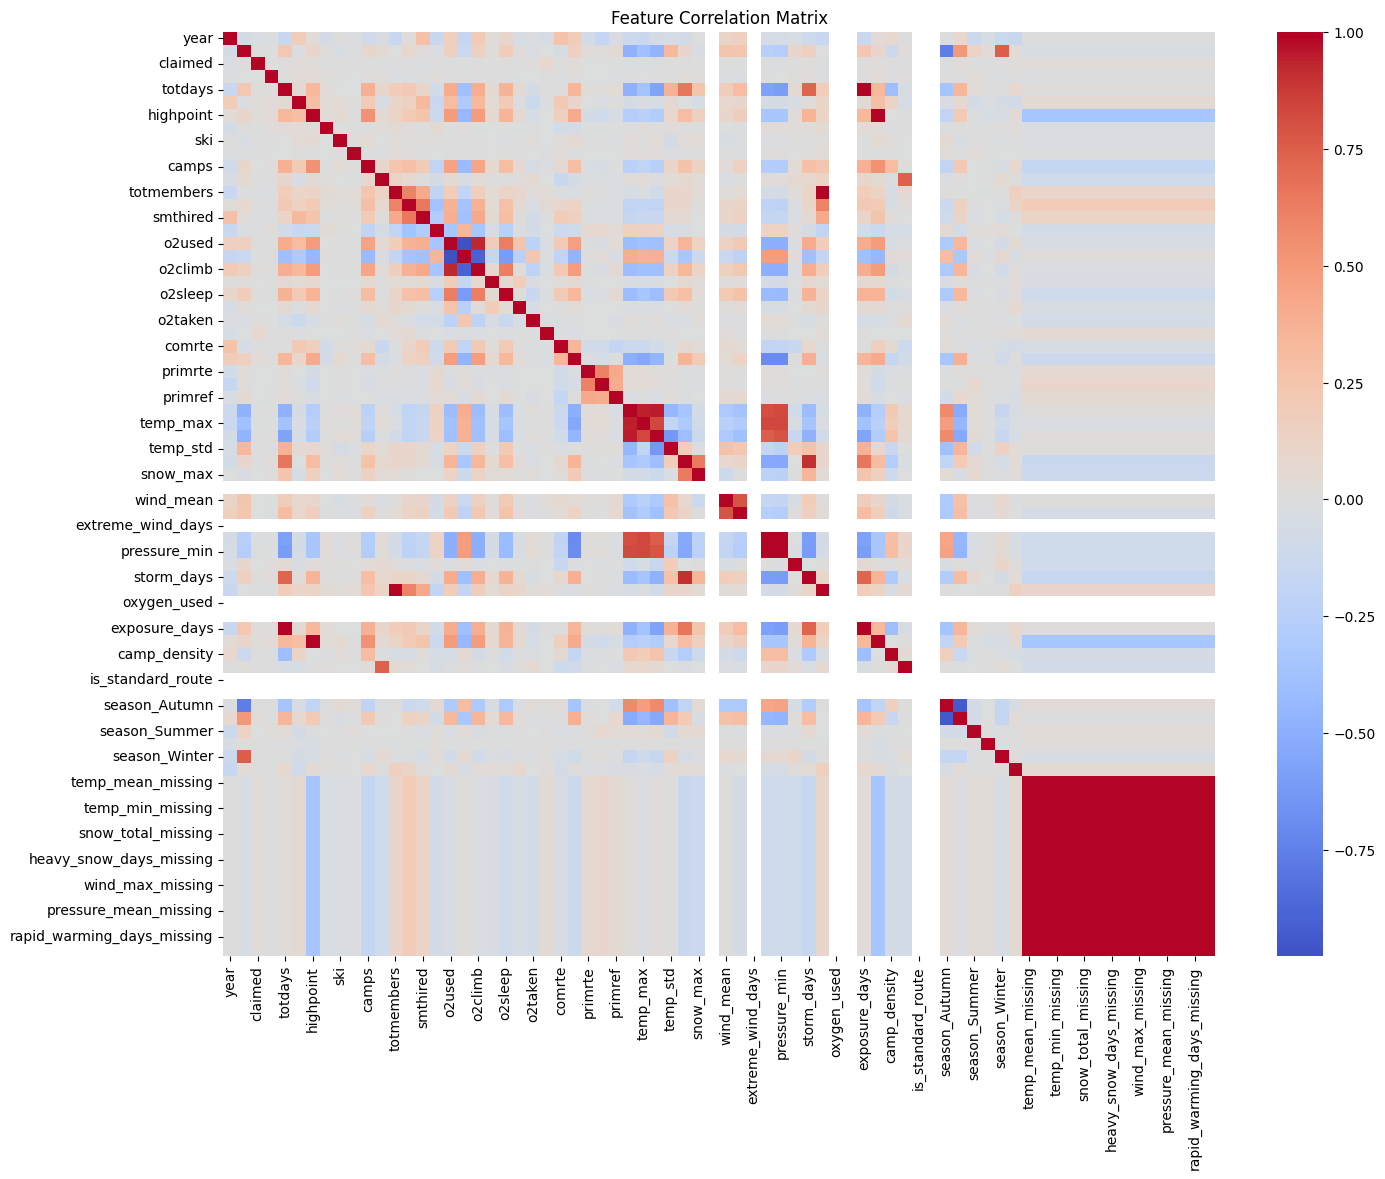

In [ ]:
#Correlation Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr_matrix = df_encoded.corr()

plt.figure(figsize=(16,12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
exped_clean['weather_missing'] = exped_clean['temp_mean_missing']

In [ ]:
missing_cols = [col for col in exped_clean.columns if '_missing' in col]
exped_clean = exped_clean.drop(columns=missing_cols)

exped_clean['weather_missing'] = (exped_full['temp_mean'].isna()).astype(int)

# Raw Baseline Model (No Feature Selection, No Imbalance Treatment)

In [ ]:
ip=df_encoded.drop('fatality',axis=1)
op=df_encoded["fatality"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    ip,
    op,
    test_size=0.3,
    stratify=op,
    random_state=42
)

         Original            Train             Test           
            Count Percentage Count Percentage Count Percentage
fatality                                                      
0            8953  94.670614  6266  94.666868  2687  94.679352
1             504   5.329386   353   5.333132   151   5.320648


<Axes: xlabel='fatality'>

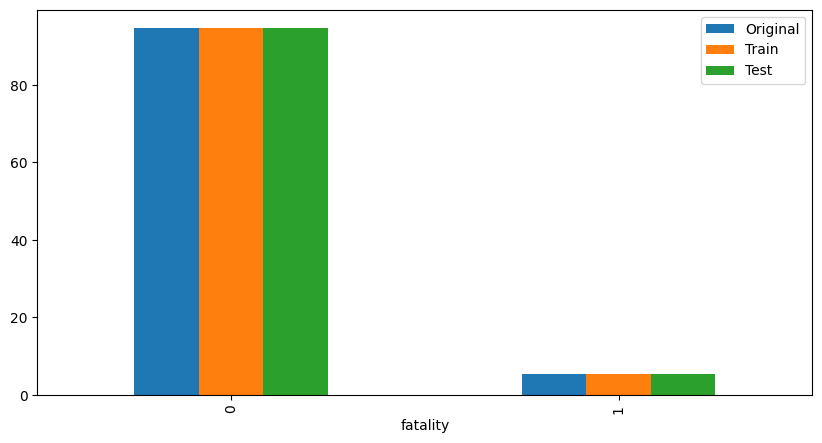

In [ ]:
#Strtification check
# Function to compute class distribution
def get_distribution(series):
    counts = series.value_counts().sort_index()
    percentages = (counts / len(series)) * 100
    return pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })

# Original distribution
original_dist = get_distribution(op)

# Train distribution
train_dist = get_distribution(y_train)

# Test distribution
test_dist = get_distribution(y_test)

# Combine all distributions
comparison = pd.concat(
    [original_dist, train_dist, test_dist],
    axis=1,
    keys=["Original", "Train", "Test"]
)

print(comparison)
comparison.xs("Percentage", level=1, axis=1).plot(kind="bar", figsize=(10,5))

In [ ]:
import pandas as pd
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


def train_and_evaluate_models(X_train, X_test, y_train, y_test):

    # -----------------------
    # Compute class imbalance ratio
    # -----------------------
    pos = sum(y_train == 1)
    neg = sum(y_train == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    # -----------------------
    # Models (WITH class weights)
    # -----------------------
    models = {
        "Decision Tree": DecisionTreeClassifier(
            class_weight='balanced',
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            class_weight='balanced',
            random_state=42
        ),

        "XGBoost": XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            random_state=42
        ),

        "KNN": KNeighborsClassifier(n_neighbors=5)  # no class_weight support
    }

    results = []
    detailed_reports = {}
    confusion_matrices = {}

    for model_name, model in models.items():

        # -----------------------
        # Training
        # -----------------------
        start_train = time.time()
        model.fit(X_train, y_train)
        end_train = time.time()

        train_time = end_train - start_train

        # -----------------------
        # Prediction
        # -----------------------
        start_pred = time.time()
        y_pred = model.predict(X_test)
        end_pred = time.time()

        pred_time = end_pred - start_pred

        # -----------------------
        # Metrics
        # -----------------------
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(y_test, y_pred, average='binary', zero_division=0)
        recall = recall_score(y_test, y_pred, average='binary', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='binary', zero_division=0)

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)

        # Classification report
        report = classification_report(y_test, y_pred, output_dict=True)

        confusion_matrices[model_name] = cm
        detailed_reports[model_name] = report

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision (Fatality)": precision,
            "Recall (Fatality)": recall,
            "F1 (Fatality)": f1,
            "Training_Time_sec": train_time,
            "Prediction_Time_sec": pred_time
        })

    results_df = pd.DataFrame(results)

    return results_df, confusion_matrices, detailed_reports

In [ ]:
results, confusion_matrices, reports = train_and_evaluate_models(
    X_train,
    X_test,
    y_train,
    y_test
)

print(results)


print("Confusion Matrix of Decision Tree, it-1")
print(confusion_matrices["Decision Tree"])
print("Confusion Matrix of Random Forest, it-1")
print(confusion_matrices["Random Forest"])
print("Confusion Matrix of XGBoost, it-1")
print(confusion_matrices["XGBoost"])
print("Confusion Matrix of KNN, it-1")
print(confusion_matrices["KNN"])

           Model  Accuracy  Precision (Fatality)  Recall (Fatality)  \
0  Decision Tree  0.926004              0.290780           0.271523   
1  Random Forest  0.952079              0.777778           0.139073   
2        XGBoost  0.932347              0.362416           0.357616   
3            KNN  0.946089              0.333333           0.013245   

   F1 (Fatality)  Training_Time_sec  Prediction_Time_sec  
0       0.280822           0.149753             0.003070  
1       0.235955           1.256915             0.049760  
2       0.360000           0.764052             0.016320  
3       0.025478           0.004722             0.188027  
Confusion Matrix of Decision Tree, it-1
[[2587  100]
 [ 110   41]]
Confusion Matrix of Random Forest, it-1
[[2681    6]
 [ 130   21]]
Confusion Matrix of XGBoost, it-1
[[2592   95]
 [  97   54]]
Confusion Matrix of KNN, it-1
[[2683    4]
 [ 149    2]]


In [ ]:
print("Classification Report of Decision Tree, it-1")
pd.DataFrame(reports["Decision Tree"]).transpose()

Classification Report of Decision Tree, it-1


,precision,recall,f1-score,support
0,0.959214,0.962784,0.960996,2687.000000
1,0.290780,0.271523,0.280822,151.000000
accuracy,0.926004,0.926004,0.926004,0.926004
macro avg,0.624997,0.617153,0.620909,2838.000000
weighted avg,0.923649,0.926004,0.924806,2838.000000


In [ ]:
print("Classification Report of Random Forest, it-1")
pd.DataFrame(reports["Random Forest"]).transpose()

Classification Report of Random Forest, it-1


,precision,recall,f1-score,support
0,0.953753,0.997767,0.975264,2687.000000
1,0.777778,0.139073,0.235955,151.000000
accuracy,0.952079,0.952079,0.952079,0.952079
macro avg,0.865765,0.568420,0.605609,2838.000000
weighted avg,0.944390,0.952079,0.935928,2838.000000


In [ ]:
print("Classification Report of XGBoost, it-1")
pd.DataFrame(reports["XGBoost"]).transpose()

Classification Report of XGBoost, it-1


,precision,recall,f1-score,support
0,0.963927,0.964645,0.964286,2687.000000
1,0.362416,0.357616,0.360000,151.000000
accuracy,0.932347,0.932347,0.932347,0.932347
macro avg,0.663172,0.661130,0.662143,2838.000000
weighted avg,0.931923,0.932347,0.932134,2838.000000


In [ ]:
print("Classification Report of KNN, it-1")
pd.DataFrame(reports["KNN"]).transpose()

Classification Report of KNN, it-1


,precision,recall,f1-score,support
0,0.947387,0.998511,0.972278,2687.000000
1,0.333333,0.013245,0.025478,151.000000
accuracy,0.946089,0.946089,0.946089,0.946089
macro avg,0.640360,0.505878,0.498878,2838.000000
weighted avg,0.914715,0.946089,0.921902,2838.000000


# Feaature Selection

# Step - 1, Conventational Method

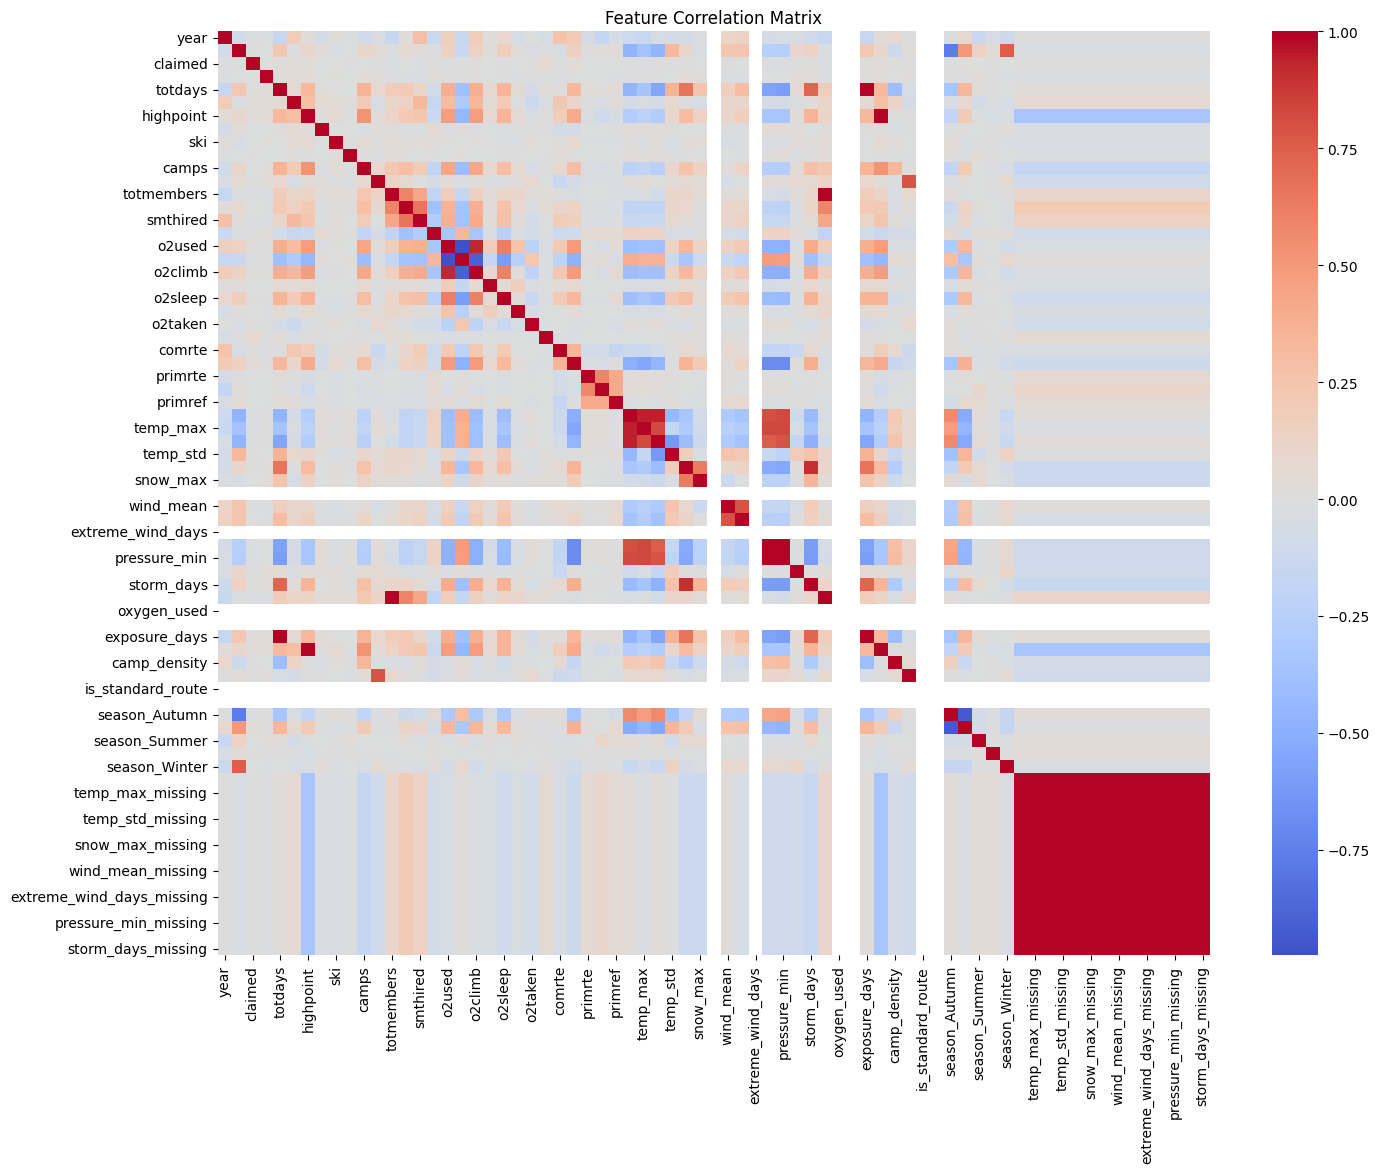

In [ ]:
#Correlation Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr_matrix = X_train.corr()

plt.figure(figsize=(16,12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title("Feature Correlation Matrix")
plt.show()

Number of features before: 71
Number of features after: 48

Dropped columns due to high correlation:
['o2none', 'o2climb', 'temp_max', 'temp_min', 'pressure_min', 'storm_days', 'team_size', 'exposure_days', 'elevation_risk', 'season_Spring', 'temp_max_missing', 'temp_min_missing', 'temp_std_missing', 'snow_total_missing', 'snow_max_missing', 'heavy_snow_days_missing', 'wind_mean_missing', 'wind_max_missing', 'extreme_wind_days_missing', 'pressure_mean_missing', 'pressure_min_missing', 'rapid_warming_days_missing', 'storm_days_missing']


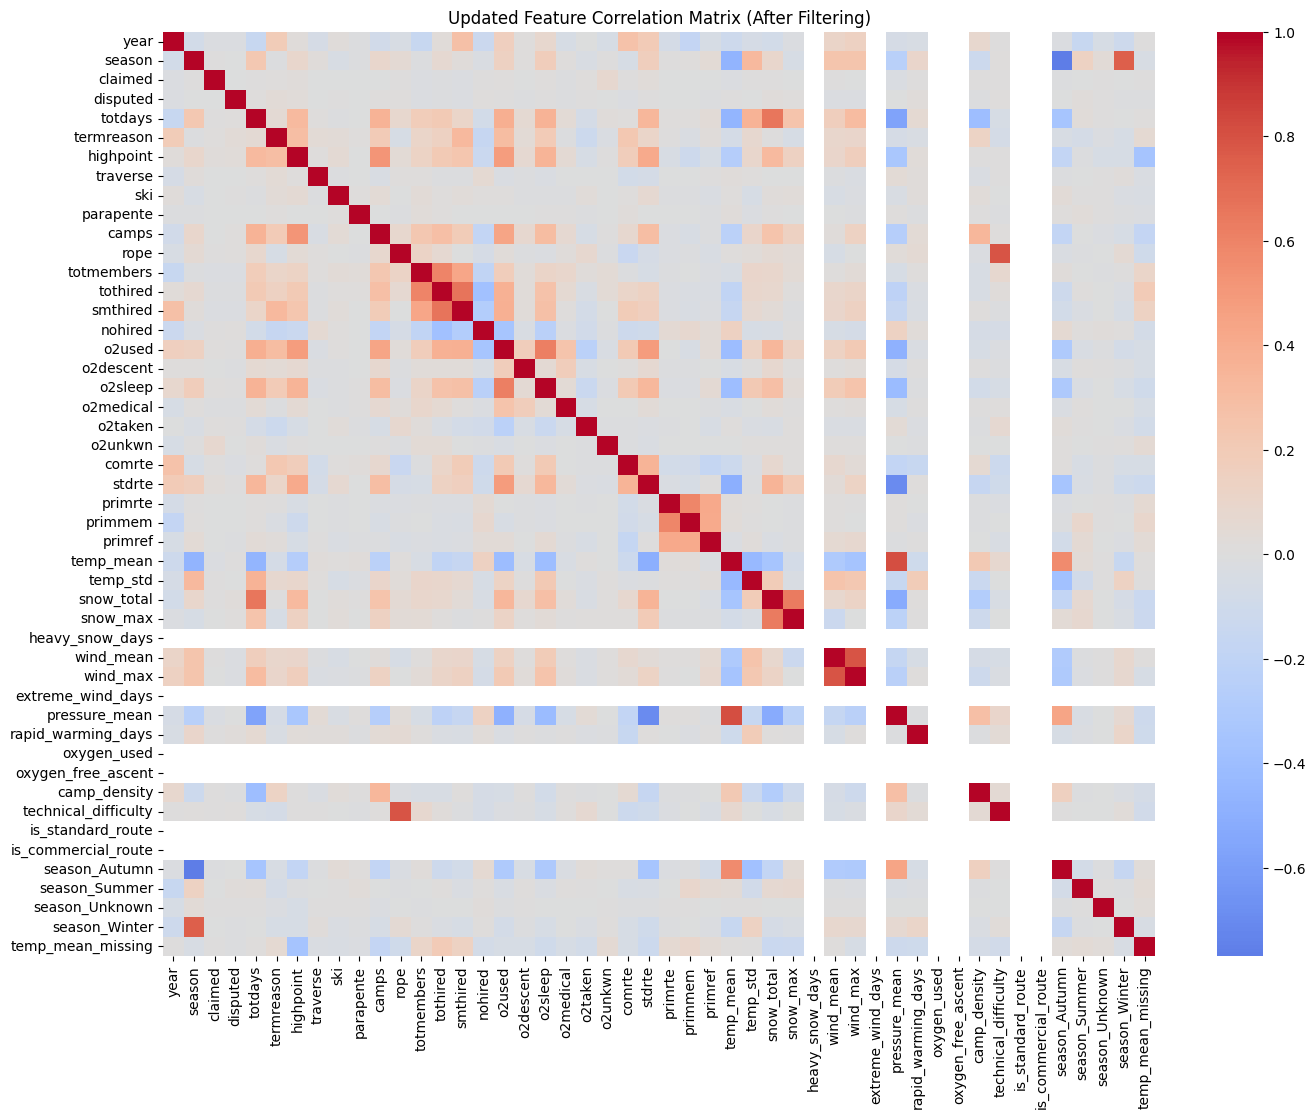

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def correlation_feature_filter(X, threshold=0.90):
    """
    Removes highly correlated features from dataset.

    Returns:
    - X_reduced: Updated dataset
    - dropped_cols: List of dropped columns
    """

    # Compute correlation matrix
    corr_matrix = X.corr().abs()

    # Upper triangle (to avoid duplicate pairs)
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    # Find columns to drop
    dropped_cols = [
        column for column in upper.columns if any(upper[column] > threshold)
    ]

    # Drop columns
    X_reduced = X.drop(columns=dropped_cols)

    return X_reduced, dropped_cols


# =========================
# APPLY ON TRAINING DATA
# =========================

X_train_filtered, dropped_columns = correlation_feature_filter(X_train, threshold=0.90)

print("Number of features before:", X_train.shape[1])
print("Number of features after:", X_train_filtered.shape[1])

print("\nDropped columns due to high correlation:")
print(dropped_columns)


# =========================
# APPLY SAME COLUMNS TO TEST DATA
# =========================

X_test_filtered = X_test.drop(columns=dropped_columns)


# =========================
# PLOT UPDATED HEATMAP
# =========================

corr_matrix_filtered = X_train_filtered.corr()

plt.figure(figsize=(16,12))
sns.heatmap(corr_matrix_filtered, cmap='coolwarm', center=0)
plt.title("Updated Feature Correlation Matrix (After Filtering)")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score

from xgboost import XGBClassifier


# =========================================
# STEP 1: L1 FEATURE SELECTION (PRE-FILTER)
# =========================================

def l1_feature_selection(X_train, y_train):

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)

    l1_model = LogisticRegression(
        penalty='l1',
        solver='liblinear',
        class_weight='balanced',
        max_iter=1000
    )

    l1_model.fit(X_scaled, y_train)

    coef = l1_model.coef_.ravel()
    selected = X_train.columns[coef != 0]

    print(f"L1 selected {len(selected)} features out of {X_train.shape[1]}")

    return list(selected)


# =========================================
# STEP 2: CUSTOM SCORING FUNCTION
# =========================================

def custom_score(y_true, y_pred):

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Weighted score (recall-focused)
    score = (0.5 * recall) + (0.3 * f1) + (0.2 * precision)

    return score


# =========================================
# STEP 3: CROSS-VALIDATION EVALUATION
# =========================================

def evaluate_feature_subset(X, y, features):

    X_sub = X[features]

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    scores = []

    for train_idx, val_idx in skf.split(X_sub, y):

        X_tr, X_val = X_sub.iloc[train_idx], X_sub.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

        pos = sum(y_tr == 1)
        neg = sum(y_tr == 0)
        scale_pos_weight = neg / pos if pos != 0 else 1

        model = XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1
        )

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)

        scores.append(custom_score(y_val, y_pred))

    return np.mean(scores)


# =========================================
# STEP 4: GREEDY FEATURE SELECTION
# =========================================

def xgb_feature_selection(X_train, y_train, initial_features):

    current_features = initial_features.copy()
    best_score = evaluate_feature_subset(X_train, y_train, current_features)

    print(f"Initial score: {best_score:.4f} with {len(current_features)} features")

    improved = True

    while improved:
        improved = False
        scores = []

        for feature in current_features:
            trial_features = [f for f in current_features if f != feature]

            if len(trial_features) == 0:
                continue

            score = evaluate_feature_subset(X_train, y_train, trial_features)
            scores.append((feature, score))

        # Find best removal
        feature_to_remove, new_score = max(scores, key=lambda x: x[1])

        if new_score > best_score:
            print(f"Removing: {feature_to_remove} → Score improved: {new_score:.4f}")
            current_features.remove(feature_to_remove)
            best_score = new_score
            improved = True

    print(f"\nFinal selected features: {len(current_features)}")
    print(f"Final score: {best_score:.4f}")

    return current_features


# =========================================
# STEP 5: FULL PIPELINE FUNCTION
# =========================================

def embedded_feature_selection_pipeline(X_train, X_test, y_train):

    # Step 1: L1 pre-filter
    l1_features = l1_feature_selection(X_train, y_train)

    X_train_l1 = X_train[l1_features]

    # Step 2: XGBoost-based selection
    selected_features = xgb_feature_selection(
        X_train_l1,
        y_train,
        list(X_train_l1.columns)
    )

    # Step 3: Final datasets
    X_train_selected = X_train[selected_features]
    X_test_selected = X_test[selected_features]

    return selected_features, X_train_selected, X_test_selected

In [ ]:
selected_features, X_train_selected, X_test_selected = embedded_feature_selection_pipeline(
    X_train_filtered,
    X_test_filtered,
    y_train
)

print("\nSelected Features:")
print(selected_features)

L1 selected 41 features out of 48
Initial score: 0.4161 with 41 features
Removing: wind_mean → Score improved: 0.4242
Removing: stdrte → Score improved: 0.4309
Removing: temp_mean_missing → Score improved: 0.4338
Removing: parapente → Score improved: 0.4349
Removing: primmem → Score improved: 0.4370

Final selected features: 36
Final score: 0.4370

Selected Features:
['year', 'season', 'claimed', 'disputed', 'totdays', 'termreason', 'highpoint', 'traverse', 'ski', 'camps', 'rope', 'totmembers', 'tothired', 'smthired', 'nohired', 'o2used', 'o2descent', 'o2sleep', 'o2medical', 'o2taken', 'o2unkwn', 'comrte', 'primrte', 'primref', 'temp_mean', 'temp_std', 'snow_total', 'snow_max', 'wind_max', 'pressure_mean', 'rapid_warming_days', 'camp_density', 'technical_difficulty', 'season_Autumn', 'season_Summer', 'season_Unknown']


In [ ]:
import pandas as pd
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


def train_and_evaluate_models(X_train, X_test, y_train, y_test):

    # -----------------------
    # Compute class imbalance ratio
    # -----------------------
    pos = sum(y_train == 1)
    neg = sum(y_train == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    # -----------------------
    # Models
    # -----------------------
    models = {
        "Decision Tree": DecisionTreeClassifier(
            class_weight='balanced',
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            class_weight='balanced',
            random_state=42
        ),

        "XGBoost": XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            random_state=42
        ),

        "KNN": KNeighborsClassifier(n_neighbors=5)
    }

    overall_results = []
    classwise_results = []
    confusion_matrices = {}

    # -----------------------
    # Loop over models
    # -----------------------
    for model_name, model in models.items():

        # ---- Training ----
        start_train = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - start_train

        # ---- Prediction ----
        start_pred = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - start_pred

        # ---- Overall Metrics ----
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='binary', zero_division=0)
        recall = recall_score(y_test, y_pred, average='binary', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='binary', zero_division=0)

        overall_results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision (Fatality)": precision,
            "Recall (Fatality)": recall,
            "F1 (Fatality)": f1,
            "Training_Time_sec": train_time,
            "Prediction_Time_sec": pred_time
        })

        # ---- Confusion Matrix ----
        cm = confusion_matrix(y_test, y_pred)
        confusion_matrices[model_name] = cm

        # ---- Classification Report ----
        report = classification_report(y_test, y_pred, output_dict=True)

        for cls in ['0', '1']:
            classwise_results.append({
                "Model": model_name,
                "Class": cls,
                "Precision": report[cls]['precision'],
                "Recall": report[cls]['recall'],
                "F1-score": report[cls]['f1-score'],
                "Support": report[cls]['support']
            })

        # Add macro & weighted averages
        for avg_type in ['macro avg', 'weighted avg']:
            classwise_results.append({
                "Model": model_name,
                "Class": avg_type,
                "Precision": report[avg_type]['precision'],
                "Recall": report[avg_type]['recall'],
                "F1-score": report[avg_type]['f1-score'],
                "Support": report[avg_type]['support']
            })

    # -----------------------
    # Convert to DataFrames
    # -----------------------
    overall_df = pd.DataFrame(overall_results)
    classwise_df = pd.DataFrame(classwise_results)

    return overall_df, classwise_df, confusion_matrices

In [ ]:
overall_df, classwise_df, confusion_matrices = train_and_evaluate_models(
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

print("=== Overall Performance ===")
print(overall_df)

print("\n=== Class-wise Performance ===")
print(classwise_df)

=== Overall Performance ===
           Model  Accuracy  Precision (Fatality)  Recall (Fatality)  \
0  Decision Tree  0.925300              0.283688           0.264901   
1  Random Forest  0.952784              0.729730           0.178808   
2        XGBoost  0.928118              0.335404           0.357616   
3            KNN  0.942565              0.071429           0.006623   

   F1 (Fatality)  Training_Time_sec  Prediction_Time_sec  
0       0.273973           0.087168             0.002276  
1       0.287234           1.130705             0.039029  
2       0.346154           0.235114             0.011820  
3       0.012121           0.002899             0.158653  

=== Class-wise Performance ===
            Model         Class  Precision    Recall  F1-score  Support
0   Decision Tree             0   0.958843  0.962412  0.960624   2687.0
1   Decision Tree             1   0.283688  0.264901  0.273973    151.0
2   Decision Tree     macro avg   0.621266  0.613656  0.617298   2838.0
3

# Metaherustic Optimiser

In [ ]:
# =========================================
# IMPORTS
# =========================================
import numpy as np
import pandas as pd
import random

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score

from xgboost import XGBClassifier


# =========================================
# CUSTOM SCORE (RECALL-FOCUSED)
# =========================================
def custom_score(y_true, y_pred):
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    return (0.5 * recall) + (0.3 * f1) + (0.2 * precision)


# =========================================
# EVALUATOR (NO DATA LEAKAGE)
# =========================================
def create_evaluator(Xtr, Xval, ytr, yval):

    pos = sum(ytr == 1)
    neg = sum(ytr == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    def evaluator(mask):

        if np.sum(mask) == 0:
            return 0

        cols = np.where(mask == 1)[0]

        model = XGBClassifier(
            n_estimators=50,
            max_depth=6,
            learning_rate=0.1,
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            tree_method="hist",
            device="cuda",
            verbosity=0,
            max_bin=256,
            random_state=42
        )

        model.fit(Xtr.iloc[:, cols], ytr)
        preds = model.predict(Xval.iloc[:, cols])

        return custom_score(yval, preds)

    return evaluator


# =========================================
# FITNESS FUNCTION
# =========================================
def fitness(mask, evaluator, num_features, alpha=0.02):
    score = evaluator(mask)
    penalty = alpha * (np.sum(mask) / num_features)
    return score - penalty


# =========================================
# GA OPTIMIZER
# =========================================
def GA_feature_selection(X_train, y_train, evaluator, pop_size=20, generations=30):

    num_features = X_train.shape[1]
    population = np.random.randint(0, 2, (pop_size, num_features))
    scores = np.array([fitness(ind, evaluator, num_features) for ind in population])

    best = population[np.argmax(scores)]
    best_score = np.max(scores)

    for gen in range(generations):

        new_pop = [best.copy()]

        while len(new_pop) < pop_size:
            p1, p2 = random.sample(list(population), 2)

            point = np.random.randint(1, num_features - 1)
            child = np.concatenate([p1[:point], p2[point:]])

            for j in range(num_features):
                if random.random() < 0.02:
                    child[j] = 1 - child[j]

            new_pop.append(child)

        population = np.array(new_pop)

        for i in range(pop_size):
            scores[i] = fitness(population[i], evaluator, num_features)
            if scores[i] > best_score:
                best_score = scores[i]
                best = population[i].copy()

        print(f"GA Gen {gen+1} | Score {best_score:.4f} | Features {np.sum(best)}")

    return X_train.columns[np.where(best == 1)[0]]


# =========================================
# PSO OPTIMIZER
# =========================================
def PSO_feature_selection(X_train, y_train, evaluator, swarm_size=20, max_iter=30):

    num_features = X_train.shape[1]
    particles = np.random.randint(0, 2, (swarm_size, num_features))
    velocities = np.random.uniform(-1, 1, (swarm_size, num_features))

    pbest = particles.copy()
    pbest_scores = np.array([fitness(p, evaluator, num_features) for p in particles])

    gbest = pbest[np.argmax(pbest_scores)]
    gbest_score = np.max(pbest_scores)

    for it in range(max_iter):

        for i in range(swarm_size):

            r1, r2 = np.random.rand(num_features), np.random.rand(num_features)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - particles[i])
                + 1.5 * r2 * (gbest - particles[i])
            )

            prob = 1 / (1 + np.exp(-velocities[i]))
            particles[i] = (prob > np.random.rand(num_features)).astype(int)

            score = fitness(particles[i], evaluator, num_features)

            if score > pbest_scores[i]:
                pbest[i] = particles[i]
                pbest_scores[i] = score

                if score > gbest_score:
                    gbest = particles[i]
                    gbest_score = score

        print(f"PSO Iter {it+1} | Score {gbest_score:.4f} | Features {np.sum(gbest)}")

    return X_train.columns[np.where(gbest == 1)[0]]


# =========================================
# GWO OPTIMIZER
# =========================================
def GWO_feature_selection(X_train, y_train, evaluator, pack_size=20, max_iter=30):

    num_features = X_train.shape[1]
    wolves = np.random.randint(0, 2, (pack_size, num_features))
    scores = np.array([fitness(w, evaluator, num_features) for w in wolves])

    for it in range(max_iter):

        idx = np.argsort(scores)
        alpha, beta, delta = wolves[idx[-1]], wolves[idx[-2]], wolves[idx[-3]]

        for i in range(pack_size):

            new_pos = (alpha + beta + delta) / 3
            prob = 1 / (1 + np.exp(-new_pos))
            wolves[i] = (prob > np.random.rand(num_features)).astype(int)

        scores = np.array([fitness(w, evaluator, num_features) for w in wolves])

        print(f"GWO Iter {it+1} | Score {np.max(scores):.4f}")

    best = wolves[np.argmax(scores)]
    return X_train.columns[np.where(best == 1)[0]]


# =========================================
# EVO OPTIMIZER
# =========================================
def EVO_feature_selection(X_train, y_train, evaluator, pop_size=20, max_iter=30):

    num_features = X_train.shape[1]
    population = np.random.randint(0, 2, (pop_size, num_features))
    scores = np.array([fitness(p, evaluator, num_features) for p in population])

    best = population[np.argmax(scores)]
    best_score = np.max(scores)

    for it in range(max_iter):

        center = np.mean(population, axis=0)

        for i in range(pop_size):

            neighbor = population[random.randint(0, pop_size - 1)]

            tau = np.random.rand(4)

            new = population[i] + (tau[0]*best - tau[1]*center)
            new += (tau[2]*best - tau[3]*neighbor)

            prob = 1 / (1 + np.exp(-new))
            new = (prob > 0.5).astype(int)

            score = fitness(new, evaluator, num_features)

            if score > scores[i]:
                population[i] = new
                scores[i] = score

                if score > best_score:
                    best = new
                    best_score = score

        print(f"EVO Iter {it+1} | Score {best_score:.4f} | Features {np.sum(best)}")

    return X_train.columns[np.where(best == 1)[0]]


# =========================================
# FOA OPTIMIZER
# =========================================
def FOA_feature_selection(X_train, y_train, evaluator, pop_size=20, max_iter=30):

    num_features = X_train.shape[1]
    forest = np.random.randint(0, 2, (pop_size, num_features))
    scores = np.array([fitness(f, evaluator, num_features) for f in forest])

    best = forest[np.argmax(scores)]
    best_score = np.max(scores)

    for it in range(max_iter):

        new_forest = []

        for tree in forest:
            seed = tree.copy()
            idx = np.random.randint(num_features)
            seed[idx] = 1 - seed[idx]
            new_forest.append(seed)

        combined = np.vstack((forest, new_forest))
        combined_scores = np.array([fitness(c, evaluator, num_features) for c in combined])

        best_idx = np.argsort(combined_scores)[-pop_size:]
        forest = combined[best_idx]
        scores = combined_scores[best_idx]

        if np.max(scores) > best_score:
            best = forest[np.argmax(scores)]
            best_score = np.max(scores)

        print(f"FOA Iter {it+1} | Score {best_score:.4f} | Features {np.sum(best)}")

    return X_train.columns[np.where(best == 1)[0]]

In [ ]:
def FOA_GWO_hybrid_feature_selection(
    X_train,
    y_train,
    evaluator,
    pop_size=20,
    max_iter=30,
    alpha_penalty=0.02
):

    import numpy as np

    num_features = X_train.shape[1]

    # -----------------------------
    # INITIALIZATION
    # -----------------------------
    population = np.random.randint(0, 2, (pop_size, num_features))

    scores = np.array([
        fitness(ind, evaluator, num_features, alpha_penalty)
        for ind in population
    ])

    best = population[np.argmax(scores)]
    best_score = np.max(scores)

    print("\n===== FOA-GWO HYBRID STARTED =====")
    print("Initial Best Score:", best_score)

    # -----------------------------
    # MAIN LOOP
    # -----------------------------
    for iteration in range(max_iter):

        # =================================
        # 🔵 PHASE 1: FOA (Exploration)
        # =================================
        new_population = []

        for i in range(pop_size):

            tree = population[i].copy()

            # Local seeding (mutation)
            seed = tree.copy()
            idx = np.random.randint(num_features)
            seed[idx] = 1 - seed[idx]

            new_population.append(seed)

        new_population = np.array(new_population)

        # Combine populations
        combined = np.vstack((population, new_population))

        combined_scores = np.array([
            fitness(ind, evaluator, num_features, alpha_penalty)
            for ind in combined
        ])

        # Select top individuals
        top_indices = np.argsort(combined_scores)[-pop_size:]

        population = combined[top_indices]
        scores = combined_scores[top_indices]

        # =================================
        # 🟢 PHASE 2: GWO (Exploitation)
        # =================================
        sorted_idx = np.argsort(scores)

        alpha = population[sorted_idx[-1]]
        beta  = population[sorted_idx[-2]]
        delta = population[sorted_idx[-3]]

        a = 2 - iteration * (2 / max_iter)

        for i in range(pop_size):

            wolf = population[i].copy()

            r1, r2 = np.random.rand(2)
            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(C1 * alpha - wolf)
            X1 = alpha - A1 * D_alpha

            r1, r2 = np.random.rand(2)
            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(C2 * beta - wolf)
            X2 = beta - A2 * D_beta

            r1, r2 = np.random.rand(2)
            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(C3 * delta - wolf)
            X3 = delta - A3 * D_delta

            new_position = (X1 + X2 + X3) / 3

            prob = 1 / (1 + np.exp(-new_position))
            population[i] = (prob > np.random.rand(num_features)).astype(int)

        # Re-evaluate after GWO update
        scores = np.array([
            fitness(ind, evaluator, num_features, alpha_penalty)
            for ind in population
        ])

        # Update global best
        if np.max(scores) > best_score:
            best = population[np.argmax(scores)]
            best_score = np.max(scores)

        print(
            f"Iteration {iteration+1}/{max_iter} | "
            f"Best Score = {best_score:.5f} | "
            f"Features = {np.sum(best)}"
        )

    print("\n===== HYBRID OPTIMIZATION COMPLETE =====")
    print("Final Best Score:", best_score)
    print("Selected Features:", np.sum(best))

    selected_indices = np.where(best == 1)[0]
    selected_features = X_train.columns[selected_indices]

    return selected_features

In [ ]:
from joblib import Parallel, delayed

# =========================================
# RUN SINGLE OPTIMIZER
# =========================================
def run_optimizer(name, optimizer_func, X_train, y_train):

    print(f"\n===== {name} STARTED =====")
    print("Features BEFORE:", X_train.shape[1])

    Xtr, Xval, ytr, yval = train_test_split(
        X_train, y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=42
    )

    evaluator = create_evaluator(Xtr, Xval, ytr, yval)

    selected_features = optimizer_func(X_train, y_train, evaluator)

    print(f"{name} SELECTED:", len(selected_features))
    print(selected_features)

    print(f"===== {name} DONE =====\n")

    return name, selected_features


# =========================================
# RUN ALL OPTIMIZERS IN PARALLEL
# =========================================
def run_all_optimizers(X_train_filtered, X_test_filtered, y_train):

    optimizers = [
    ("GA", GA_feature_selection),
    ("PSO", PSO_feature_selection),
    ("GWO", GWO_feature_selection),
    ("EVO", EVO_feature_selection),
    ("FOA", FOA_feature_selection),
    ("FOA_GWO", FOA_GWO_hybrid_feature_selection)
]

    results = Parallel(n_jobs=1)(
        delayed(run_optimizer)(name, func, X_train_filtered, y_train)
        for name, func in optimizers
    )

    datasets = {}

    for name, features in results:

        X_train_sel = X_train_filtered[features]
        X_test_sel = X_test_filtered[features]

        datasets[name] = {
            "features": features,
            "X_train": X_train_sel,
            "X_test": X_test_sel
        }

    return datasets


# =========================================
# RUN EVERYTHING
# =========================================
datasets = run_all_optimizers(
    X_train_filtered,
    X_test_filtered,
    y_train
)


===== GA STARTED =====
Features BEFORE: 48
GA Gen 1 | Score 0.5208 | Features 21
GA Gen 2 | Score 0.5208 | Features 21
GA Gen 3 | Score 0.5208 | Features 21
GA Gen 4 | Score 0.5208 | Features 21
GA Gen 5 | Score 0.5208 | Features 21
GA Gen 6 | Score 0.5208 | Features 21
GA Gen 7 | Score 0.5447 | Features 19
GA Gen 8 | Score 0.5447 | Features 19
GA Gen 9 | Score 0.5447 | Features 19
GA Gen 10 | Score 0.5447 | Features 19
GA Gen 11 | Score 0.5447 | Features 19
GA Gen 12 | Score 0.5447 | Features 19
GA Gen 13 | Score 0.5447 | Features 19
GA Gen 14 | Score 0.5447 | Features 19
GA Gen 15 | Score 0.5447 | Features 19
GA Gen 16 | Score 0.5447 | Features 19
GA Gen 17 | Score 0.5447 | Features 19
GA Gen 18 | Score 0.5447 | Features 19
GA Gen 19 | Score 0.5447 | Features 19
GA Gen 20 | Score 0.5572 | Features 21
GA Gen 21 | Score 0.5572 | Features 21
GA Gen 22 | Score 0.5572 | Features 21
GA Gen 23 | Score 0.5572 | Features 21
GA Gen 24 | Score 0.5572 | Features 21
GA Gen 25 | Score 0.5572 | Fe

In [ ]:
def evaluate_optimizers_models(datasets, y_train, y_test):

    import pandas as pd
    import time

    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.neighbors import KNeighborsClassifier
    from xgboost import XGBClassifier

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        classification_report,
        confusion_matrix
    )

    overall_results = []
    classwise_results = []
    confusion_matrices = {}

    for opt_name, data in datasets.items():

        print(f"\n===== Evaluating Optimizer: {opt_name} =====")

        X_train = data["X_train"]
        X_test = data["X_test"]

        print("Feature Count:", X_train.shape[1])

        # Class imbalance
        pos = sum(y_train == 1)
        neg = sum(y_train == 0)
        scale_pos_weight = neg / pos if pos != 0 else 1

        models = {
            "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
            "XGBoost": XGBClassifier(
                objective='binary:logistic',
                scale_pos_weight=scale_pos_weight,
                eval_metric='logloss',
                tree_method="hist",
                device="cuda",
                random_state=42
            ),
            "KNN": KNeighborsClassifier(n_neighbors=5)
        }

        for model_name, model in models.items():

            # ---- Training ----
            start_train = time.time()
            model.fit(X_train, y_train)
            train_time = time.time() - start_train

            # ---- Prediction ----
            start_pred = time.time()
            y_pred = model.predict(X_test)
            pred_time = time.time() - start_pred

            # ---- Metrics ----
            accuracy = accuracy_score(y_test, y_pred)
            precision = precision_score(y_test, y_pred, zero_division=0)
            recall = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)

            overall_results.append({
                "Optimizer": opt_name,
                "Model": model_name,
                "Accuracy": accuracy,
                "Precision (Fatality)": precision,
                "Recall (Fatality)": recall,
                "F1 (Fatality)": f1,
                "Training_Time": train_time,
                "Prediction_Time": pred_time
            })

            # ---- Confusion Matrix ----
            confusion_matrices[(opt_name, model_name)] = confusion_matrix(y_test, y_pred)

            # ---- Class-wise Report ----
            report = classification_report(y_test, y_pred, output_dict=True)

            for cls in ['0', '1']:
                classwise_results.append({
                    "Optimizer": opt_name,
                    "Model": model_name,
                    "Class": cls,
                    "Precision": report[cls]['precision'],
                    "Recall": report[cls]['recall'],
                    "F1-score": report[cls]['f1-score'],
                    "Support": report[cls]['support']
                })

            for avg in ['macro avg', 'weighted avg']:
                classwise_results.append({
                    "Optimizer": opt_name,
                    "Model": model_name,
                    "Class": avg,
                    "Precision": report[avg]['precision'],
                    "Recall": report[avg]['recall'],
                    "F1-score": report[avg]['f1-score'],
                    "Support": report[avg]['support']
                })

    overall_df = pd.DataFrame(overall_results)
    classwise_df = pd.DataFrame(classwise_results)

    return overall_df, classwise_df, confusion_matrices

In [ ]:
from IPython.display import display

overall_df, classwise_df, confusion_matrices = evaluate_optimizers_models(
    datasets,
    y_train,
    y_test
)

print("\n===== OVERALL PERFORMANCE =====")
display(overall_df)

print("\n===== CLASS-WISE PERFORMANCE =====")
display(classwise_df)


===== Evaluating Optimizer: GA =====
Feature Count: 21

===== Evaluating Optimizer: PSO =====
Feature Count: 29

===== Evaluating Optimizer: GWO =====
Feature Count: 35

===== Evaluating Optimizer: EVO =====
Feature Count: 37

===== Evaluating Optimizer: FOA =====
Feature Count: 20

===== Evaluating Optimizer: FOA_GWO =====
Feature Count: 35

===== OVERALL PERFORMANCE =====


,Optimizer,Model,Accuracy,Precision (Fatality),Recall (Fatality),F1 (Fatality),Training_Time,Prediction_Time
0,GA,Decision Tree,0.918957,0.271676,0.311258,0.290123,0.038904,0.001699
1,GA,Random Forest,0.953136,0.680000,0.225166,0.338308,0.682463,0.037437
2,GA,XGBoost,0.919309,0.290323,0.357616,0.320475,0.158737,0.008838
3,GA,KNN,0.942213,0.240000,0.039735,0.068182,0.002774,0.099479
4,PSO,Decision Tree,0.897815,0.078788,0.086093,0.082278,0.056064,0.001930
5,PSO,Random Forest,0.943975,0.277778,0.033113,0.059172,0.926682,0.038399
6,PSO,XGBoost,0.898168,0.136842,0.172185,0.152493,0.260829,0.010545
7,PSO,KNN,0.946441,0.466667,0.046358,0.084337,0.002656,0.107220
8,GWO,Decision Tree,0.924595,0.296774,0.304636,0.300654,0.079199,0.001909
9,GWO,Random Forest,0.954545,0.805556,0.192053,0.310160,0.981574,0.035927



===== CLASS-WISE PERFORMANCE =====


,Optimizer,Model,Class,Precision,Recall,F1-score,Support
0,GA,Decision Tree,0,0.960976,0.953108,0.957025,2687.0
1,GA,Decision Tree,1,0.271676,0.311258,0.290123,151.0
2,GA,Decision Tree,macro avg,0.616326,0.632183,0.623574,2838.0
3,GA,Decision Tree,weighted avg,0.924300,0.918957,0.921542,2838.0
4,GA,Random Forest,0,0.958034,0.994045,0.975708,2687.0
...,...,...,...,...,...,...,...
91,FOA_GWO,XGBoost,weighted avg,0.928065,0.922481,0.925160,2838.0
92,FOA_GWO,KNN,0,0.948600,0.995906,0.971678,2687.0
93,FOA_GWO,KNN,1,0.352941,0.039735,0.071429,151.0
94,FOA_GWO,KNN,macro avg,0.650770,0.517821,0.521553,2838.0


In [ ]:
# Save CSV files
overall_df.to_csv("overall_performance.csv", index=False)
classwise_df.to_csv("classwise_performance.csv", index=False)

print("CSV files saved successfully.")

CSV files saved successfully.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.under_sampling import RandomUnderSampler

# 🔥 NEW IMPORT (ADDED)
from sklearn.calibration import CalibratedClassifierCV


# =========================================
# CUSTOM SCORE (UNCHANGED)
# =========================================
def custom_score(y_true, y_pred):

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    score = recall - 0.5 * fpr

    return score, recall, fpr


# =========================================
# UPDATED THRESHOLD FUNCTION (KEEP YOUR VERSION)
# =========================================
def find_best_threshold_precise(y_true, y_proba):

    best_score = -1
    best_thresh = 0.5
    best_metrics = None

    for t in np.linspace(0.10, 0.30, 41):

        y_pred = (y_proba >= t).astype(int)

        from sklearn.metrics import precision_score, recall_score

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)

        score = f1_score(y_true, y_pred, zero_division=0)

        if score > best_score:
            best_score = score
            best_thresh = t
            best_metrics = (precision, recall)

    return best_thresh, best_score, best_metrics


# =========================================
# APPLY SAMPLING (UNCHANGED)
# =========================================
def apply_sampling(method, X, y):

    if method == "SMOTE":
        sampler = SMOTE(random_state=42)

    elif method == "ADASYN":
        sampler = ADASYN(random_state=42)

    elif method == "SMOTEENN":
        sampler = SMOTEENN(random_state=42)

    elif method == "SMOTETomek":
        sampler = SMOTETomek(random_state=42)

    elif method == "UnderSampling":
        sampler = RandomUnderSampler(random_state=42)

    else:
        return X, y

    X_res, y_res = sampler.fit_resample(X, y)

    return X_res, y_res


# =========================================
# MAIN PIPELINE (UPDATED)
# =========================================
def imbalance_experiment(datasets, y_train, y_test):

    results = []

    data = datasets["FOA_GWO"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    print("\nUsing FOA_GWO Feature Set")
    print("Feature Count:", X_train.shape[1])

    pos = sum(y_train == 1)
    neg = sum(y_train == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    methods = [
        "Baseline",
        "SMOTE",
        "ADASYN",
        "SMOTEENN",
        "SMOTETomek",
        "UnderSampling"
    ]

    for method in methods:

        print(f"\n===== Method: {method} =====")

        X_res, y_res = apply_sampling(method, X_train, y_train)

        print("Resampled shape:", X_res.shape)

        # =========================================
        # 🔥 CALIBRATED MODEL (REPLACED)
        # =========================================
        base_model = XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            tree_method="hist",
            device="cuda",
            random_state=42
        )

        model = CalibratedClassifierCV(base_model, method='sigmoid', cv=3)

        model.fit(X_res, y_res)

        # =========================================
        # PREDICT PROBA
        # =========================================
        y_proba = model.predict_proba(X_test)[:, 1]

        # =========================================
        # 🔥 CORRECT FUNCTION CALL + UNPACKING
        # =========================================
        best_thresh, best_score, (precision, recall) = find_best_threshold_precise(y_test, y_proba)

        print(f"Best Threshold: {best_thresh:.3f}")
        print(f"Score: {best_score:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f}")

        results.append({
            "Method": method,
            "Best_Threshold": best_thresh,
            "Score": best_score,
            "Precision": precision,   # 🔥 CHANGED
            "Recall": recall,
            "Features": X_train.shape[1]
        })

    return pd.DataFrame(results)

In [ ]:
imbalance_results = imbalance_experiment(
    datasets,
    y_train,
    y_test
)

from IPython.display import display

print("\n===== BEST METHODS (BY SCORE) =====")
display(
    imbalance_results
    .sort_values(by="Score", ascending=False)
    .reset_index(drop=True)
)

print("\n===== BEST METHODS (BY RECALL) =====")
display(
    imbalance_results
    .sort_values(by="Recall", ascending=False)
    .reset_index(drop=True)
)


Using FOA_GWO Feature Set
Feature Count: 35

===== Method: Baseline =====
Resampled shape: (6619, 35)
Best Threshold: 0.270
Score: 0.3917 | Precision: 0.5281 | Recall: 0.3113

===== Method: SMOTE =====
Resampled shape: (12532, 35)
Best Threshold: 0.300
Score: 0.2500 | Precision: 0.1762 | Recall: 0.4305

===== Method: ADASYN =====
Resampled shape: (12556, 35)
Best Threshold: 0.275
Score: 0.2414 | Precision: 0.1602 | Recall: 0.4901

===== Method: SMOTEENN =====
Resampled shape: (10669, 35)
Best Threshold: 0.290
Score: 0.2375 | Precision: 0.1525 | Recall: 0.5364

===== Method: SMOTETomek =====
Resampled shape: (12442, 35)
Best Threshold: 0.300
Score: 0.2616 | Precision: 0.1879 | Recall: 0.4305

===== Method: UnderSampling =====
Resampled shape: (706, 35)
Best Threshold: 0.300
Score: 0.1394 | Precision: 0.0753 | Recall: 0.9272

===== BEST METHODS (BY SCORE) =====


,Method,Best_Threshold,Score,Precision,Recall,Features
0,Baseline,0.270,0.391667,0.528090,0.311258,35
1,SMOTETomek,0.300,0.261569,0.187861,0.430464,35
2,SMOTE,0.300,0.250000,0.176152,0.430464,35
3,ADASYN,0.275,0.241436,0.160173,0.490066,35
4,SMOTEENN,0.290,0.237537,0.152542,0.536424,35
5,UnderSampling,0.300,0.139373,0.075350,0.927152,35



===== BEST METHODS (BY RECALL) =====


,Method,Best_Threshold,Score,Precision,Recall,Features
0,UnderSampling,0.300,0.139373,0.075350,0.927152,35
1,SMOTEENN,0.290,0.237537,0.152542,0.536424,35
2,ADASYN,0.275,0.241436,0.160173,0.490066,35
3,SMOTE,0.300,0.250000,0.176152,0.430464,35
4,SMOTETomek,0.300,0.261569,0.187861,0.430464,35
5,Baseline,0.270,0.391667,0.528090,0.311258,35


In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV


# =========================================
# THRESHOLD SEARCH (SHARED)
# =========================================
def find_best_threshold_precise(y_true, y_proba):

    best_score = -1
    best_thresh = 0.5
    best_metrics = None

    for t in np.linspace(0.10, 0.20, 41):

        y_pred = (y_proba >= t).astype(int)

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)

        score = 0.6 * recall + 0.4 * precision

        if score > best_score:
            best_score = score
            best_thresh = t
            best_metrics = (precision, recall)

    return best_thresh, best_score, best_metrics


# =========================================
# FINAL COMPARISON FUNCTION
# =========================================
def final_model_comparison(datasets, y_train, y_test):

    data = datasets["FOA_GWO"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    print("Final Feature Count:", X_train.shape[1])

    # =========================
    # SMOTEENN (TRAIN ONLY)
    # =========================
    sampler = SMOTEENN(random_state=42)
    X_res, y_res = sampler.fit_resample(X_train, y_train)

    print("Resampled Shape:", X_res.shape)

    # =========================
    # CLASS WEIGHT
    # =========================
    pos = sum(y_res == 1)
    neg = sum(y_res == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    results = []
    classwise_all = []
    confusion_matrices = {}

    # =========================================
    # TWO MODELS: RAW vs CALIBRATED
    # =========================================
    models = {
        "Without Calibration": XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            tree_method="hist",
            device="cuda",
            random_state=42
        ),

        "With Calibration": CalibratedClassifierCV(
            XGBClassifier(
                objective='binary:logistic',
                scale_pos_weight=scale_pos_weight,
                eval_metric='logloss',
                tree_method="hist",
                device="cuda",
                random_state=42
            ),
            method='sigmoid',
            cv=3
        )
    }

    # =========================================
    # TRAIN + EVALUATE BOTH
    # =========================================
    for model_name, model in models.items():

        print(f"\n===== {model_name} =====")

        # Train
        model.fit(X_res, y_res)

        # Predict probabilities
        y_proba = model.predict_proba(X_test)[:, 1]

        # Find best threshold (IMPORTANT: SAME LOGIC)
        best_thresh, best_score, (precision, recall) = find_best_threshold_precise(y_test, y_proba)

        y_pred = (y_proba >= best_thresh).astype(int)

        print(f"Best Threshold: {best_thresh:.3f}")
        print(f"Precision: {precision:.4f} | Recall: {recall:.4f}")

        # =========================
        # METRICS
        # =========================
        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision (Fatality)": precision,
            "Recall (Fatality)": recall,
            "F1 (Fatality)": f1,
            "Best_Threshold": best_thresh
        })

        # =========================
        # CONFUSION MATRIX
        # =========================
        cm = confusion_matrix(y_test, y_pred)
        confusion_matrices[model_name] = cm

        print("Confusion Matrix:")
        print(cm)

        # =========================
        # CLASS-WISE REPORT
        # =========================
        report = classification_report(y_test, y_pred, output_dict=True)

        for cls in ['0', '1']:
            classwise_all.append({
                "Model": model_name,
                "Class": cls,
                "Precision": report[cls]['precision'],
                "Recall": report[cls]['recall'],
                "F1-score": report[cls]['f1-score'],
                "Support": report[cls]['support']
            })

    overall_df = pd.DataFrame(results)
    classwise_df = pd.DataFrame(classwise_all)

    return overall_df, classwise_df, confusion_matrices

In [ ]:
overall_cmp, classwise_cmp, cm_cmp = final_model_comparison(
    datasets,
    y_train,
    y_test
)

from IPython.display import display

print("\n===== OVERALL COMPARISON =====")
display(overall_cmp)

print("\n===== CLASS-WISE COMPARISON =====")
display(classwise_cmp)

Final Feature Count: 35
Resampled Shape: (10669, 35)

===== Without Calibration =====
Best Threshold: 0.103
Precision: 0.1225 | Recall: 0.6159
Confusion Matrix:
[[2021  666]
 [  58   93]]

===== With Calibration =====
Best Threshold: 0.128
Precision: 0.1609 | Recall: 0.5828
Confusion Matrix:
[[2228  459]
 [  63   88]]

===== OVERALL COMPARISON =====


,Model,Accuracy,Precision (Fatality),Recall (Fatality),F1 (Fatality),Best_Threshold
0,Without Calibration,0.744891,0.122530,0.615894,0.204396,0.1025
1,With Calibration,0.816068,0.160878,0.582781,0.252149,0.1275



===== CLASS-WISE COMPARISON =====


,Model,Class,Precision,Recall,F1-score,Support
0,Without Calibration,0,0.972102,0.752140,0.848091,2687.0
1,Without Calibration,1,0.122530,0.615894,0.204396,151.0
2,With Calibration,0,0.972501,0.829178,0.895139,2687.0
3,With Calibration,1,0.160878,0.582781,0.252149,151.0


In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV


# =========================================
# THRESHOLD SEARCH (UNCHANGED)
# =========================================
def find_best_threshold_precise(y_true, y_proba):

    best_score = -1
    best_thresh = 0.5
    best_metrics = None

    for t in np.linspace(0.10, 0.20, 41):

        y_pred = (y_proba >= t).astype(int)

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)

        score = 0.6 * recall + 0.4 * precision

        if score > best_score:
            best_score = score
            best_thresh = t
            best_metrics = (precision, recall)

    return best_thresh, best_score, best_metrics


# =========================================
# FINAL COMPARISON FUNCTION (BASELINE FIXED)
# =========================================
def final_model_comparison(datasets, y_train, y_test):

    data = datasets["FOA_GWO"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    print("Final Feature Count:", X_train.shape[1])

    # =========================================
    # 🚨 NO RESAMPLING (IMPORTANT CHANGE)
    # =========================================
    X_res, y_res = X_train.copy(), y_train.copy()

    print("Training on ORIGINAL data (No resampling)")
    print("Train Shape:", X_res.shape)

    # =========================================
    # CLASS WEIGHT (UNCHANGED)
    # =========================================
    pos = sum(y_res == 1)
    neg = sum(y_res == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    results = []
    classwise_all = []
    confusion_matrices = {}

    # =========================================
    # TWO MODELS: RAW vs CALIBRATED
    # =========================================
    models = {
        "Without Calibration": XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            tree_method="hist",
            device="cuda",
            random_state=42
        ),

        "With Calibration": CalibratedClassifierCV(
            XGBClassifier(
                objective='binary:logistic',
                scale_pos_weight=scale_pos_weight,
                eval_metric='logloss',
                tree_method="hist",
                device="cuda",
                random_state=42
            ),
            method='sigmoid',
            cv=3
        )
    }

    # =========================================
    # TRAIN + EVALUATE
    # =========================================
    for model_name, model in models.items():

        print(f"\n===== {model_name} =====")

        # Train
        model.fit(X_res, y_res)

        # Predict probabilities
        y_proba = model.predict_proba(X_test)[:, 1]

        # SAME threshold logic
        best_thresh, best_score, (precision, recall) = find_best_threshold_precise(y_test, y_proba)

        y_pred = (y_proba >= best_thresh).astype(int)

        print(f"Best Threshold: {best_thresh:.3f}")
        print(f"Precision: {precision:.4f} | Recall: {recall:.4f}")

        # =========================
        # METRICS
        # =========================
        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision (Fatality)": precision,
            "Recall (Fatality)": recall,
            "F1 (Fatality)": f1,
            "Best_Threshold": best_thresh
        })

        # =========================
        # CONFUSION MATRIX
        # =========================
        cm = confusion_matrix(y_test, y_pred)
        confusion_matrices[model_name] = cm

        print("Confusion Matrix:")
        print(cm)

        # =========================
        # CLASS-WISE REPORT
        # =========================
        report = classification_report(y_test, y_pred, output_dict=True)

        for cls in ['0', '1']:
            classwise_all.append({
                "Model": model_name,
                "Class": cls,
                "Precision": report[cls]['precision'],
                "Recall": report[cls]['recall'],
                "F1-score": report[cls]['f1-score'],
                "Support": report[cls]['support']
            })

    overall_df = pd.DataFrame(results)
    classwise_df = pd.DataFrame(classwise_all)

    return overall_df, classwise_df, confusion_matrices


# =========================================
# RUN
# =========================================
overall_cmp, classwise_cmp, cm_cmp = final_model_comparison(
    datasets,
    y_train,
    y_test
)

from IPython.display import display

print("\n===== OVERALL COMPARISON =====")
display(overall_cmp)

print("\n===== CLASS-WISE COMPARISON =====")
display(classwise_cmp)

Final Feature Count: 35
Training on ORIGINAL data (No resampling)
Train Shape: (6619, 35)

===== Without Calibration =====
Best Threshold: 0.103
Precision: 0.1511 | Recall: 0.5695
Confusion Matrix:
[[2204  483]
 [  65   86]]

===== With Calibration =====
Best Threshold: 0.105
Precision: 0.2952 | Recall: 0.4437
Confusion Matrix:
[[2527  160]
 [  84   67]]

===== OVERALL COMPARISON =====


,Model,Accuracy,Precision (Fatality),Recall (Fatality),F1 (Fatality),Best_Threshold
0,Without Calibration,0.806906,0.151142,0.569536,0.238889,0.1025
1,With Calibration,0.914024,0.295154,0.443709,0.354497,0.1050



===== CLASS-WISE COMPARISON =====


,Model,Class,Precision,Recall,F1-score,Support
0,Without Calibration,0,0.971353,0.820246,0.889427,2687.0
1,Without Calibration,1,0.151142,0.569536,0.238889,151.0
2,With Calibration,0,0.967828,0.940454,0.953945,2687.0
3,With Calibration,1,0.295154,0.443709,0.354497,151.0



========== FINAL PIPELINE START ==========

Final Feature Count: 35
Training on ORIGINAL data (No resampling)

===== FINAL METRICS =====
Accuracy: 0.9168
Precision: 0.3005
Recall: 0.4238
F1: 0.3516

Confusion Matrix:
[[2538  149]
 [  87   64]]

========== VISUALIZATIONS ==========



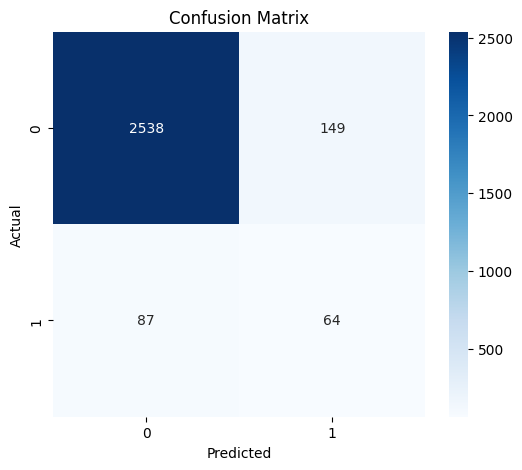

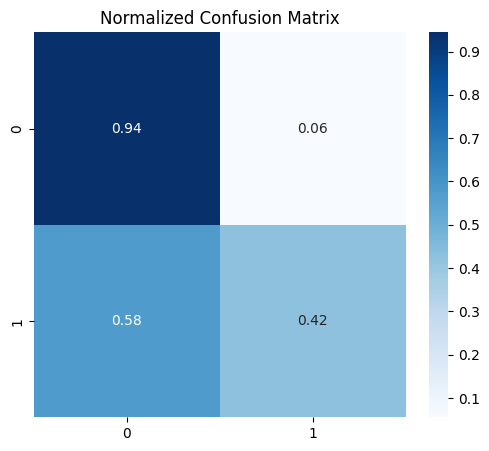

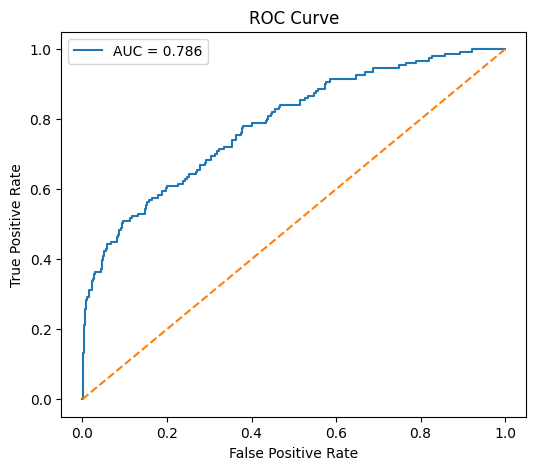

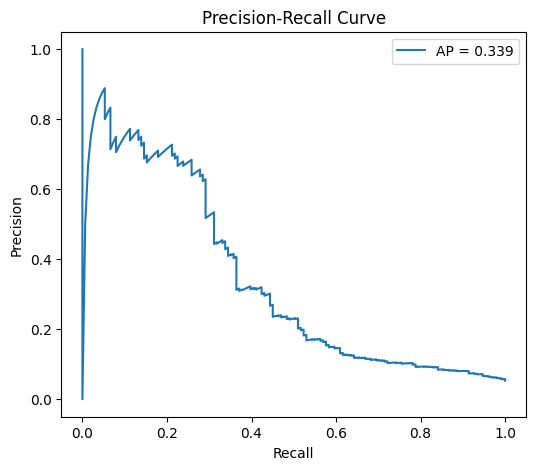

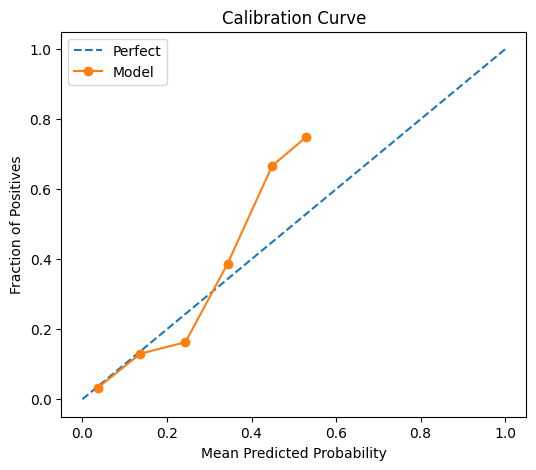

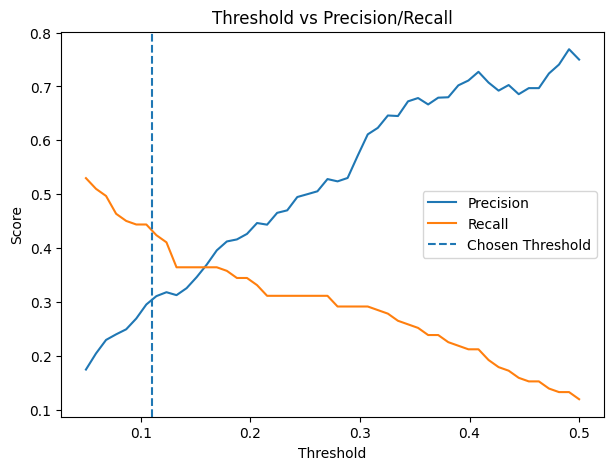

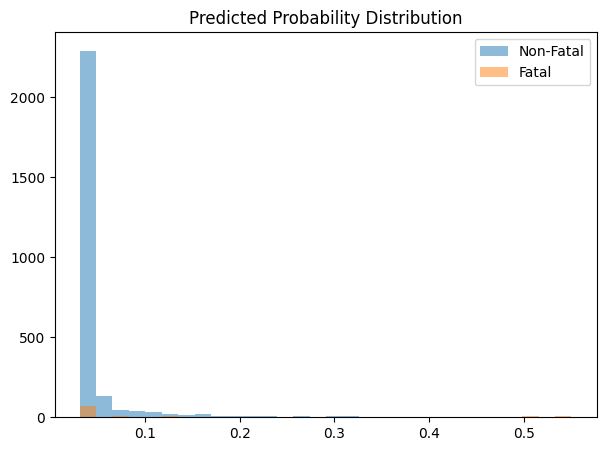

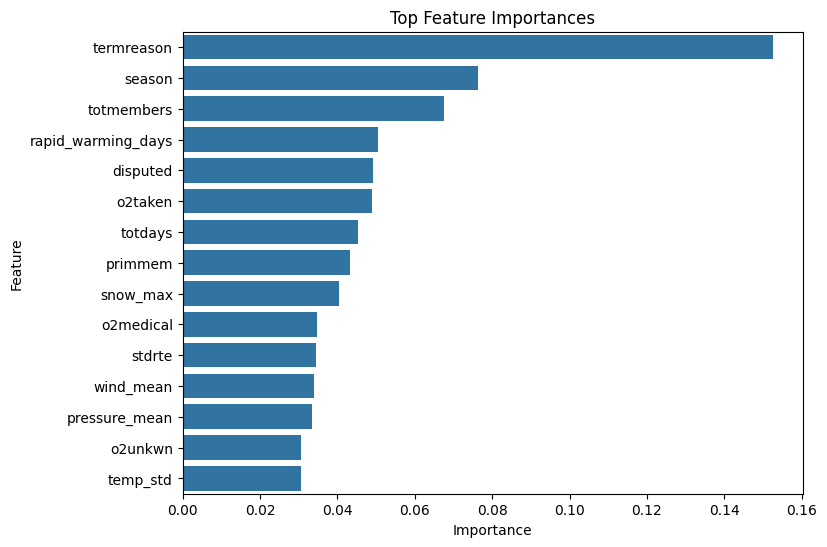


========== PIPELINE COMPLETE ==========



In [ ]:
# =========================================
# FINAL PIPELINE (CORRECTED - NO RESAMPLING)
# =========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from xgboost import XGBClassifier


def final_pipeline_with_visualization(datasets, y_train, y_test):

    print("\n========== FINAL PIPELINE START ==========\n")

    # =========================
    # LOAD DATA
    # =========================
    data = datasets["FOA_GWO"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    print("Final Feature Count:", X_train.shape[1])
    print("Training on ORIGINAL data (No resampling)")

    # =========================
    # CLASS WEIGHT (IMPORTANT)
    # =========================
    pos = sum(y_train == 1)
    neg = sum(y_train == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    # =========================
    # MODEL
    # =========================
    base_model = XGBClassifier(
        objective='binary:logistic',
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        tree_method="hist",
        device="cuda",
        random_state=42
    )

    model = CalibratedClassifierCV(base_model, method='sigmoid', cv=3)
    model.fit(X_train, y_train)

    # =========================
    # PREDICTION
    # =========================
    threshold = 0.11   # your optimized value

    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    # =========================
    # METRICS
    # =========================
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("\n===== FINAL METRICS =====")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1: {f1:.4f}")

    # =========================
    # CONFUSION MATRIX
    # =========================
    cm = confusion_matrix(y_test, y_pred)

    print("\nConfusion Matrix:")
    print(cm)

    # =========================================
    # VISUALIZATIONS
    # =========================================

    print("\n========== VISUALIZATIONS ==========\n")

    # 1. Confusion Matrix
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # 2. Normalized Confusion Matrix
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(6,5))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues')
    plt.title("Normalized Confusion Matrix")
    plt.show()

    # 3. ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],'--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()

    # 4. Precision-Recall Curve
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)

    plt.figure(figsize=(6,5))
    plt.plot(recall_curve, precision_curve, label=f"AP = {pr_auc:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()
    plt.show()

    # 5. Calibration Curve
    frac_pos, mean_pred = calibration_curve(y_test, y_proba, n_bins=10)

    plt.figure(figsize=(6,5))
    plt.plot([0,1],[0,1],'--', label="Perfect")
    plt.plot(mean_pred, frac_pos, marker='o', label="Model")
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Fraction of Positives")
    plt.title("Calibration Curve")
    plt.legend()
    plt.show()

    # 6. Threshold vs Precision-Recall
    thresholds = np.linspace(0.05, 0.5, 50)
    precs, recs = [], []

    for t in thresholds:
        pred = (y_proba >= t).astype(int)
        precs.append(precision_score(y_test, pred, zero_division=0))
        recs.append(recall_score(y_test, pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, precs, label="Precision")
    plt.plot(thresholds, recs, label="Recall")
    plt.axvline(threshold, linestyle='--', label="Chosen Threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title("Threshold vs Precision/Recall")
    plt.legend()
    plt.show()

    # 7. Probability Distribution
    plt.figure(figsize=(7,5))
    plt.hist(y_proba[y_test==0], bins=30, alpha=0.5, label="Non-Fatal")
    plt.hist(y_proba[y_test==1], bins=30, alpha=0.5, label="Fatal")
    plt.legend()
    plt.title("Predicted Probability Distribution")
    plt.show()

    # 8. Feature Importance (fixed)
    try:
        importances = model.calibrated_classifiers_[0].estimator.feature_importances_

        df_imp = pd.DataFrame({
            "Feature": X_test.columns,
            "Importance": importances
        }).sort_values(by="Importance", ascending=False)

        plt.figure(figsize=(8,6))
        sns.barplot(x="Importance", y="Feature", data=df_imp.head(15))
        plt.title("Top Feature Importances")
        plt.show()

    except:
        print("Feature importance not available")

    print("\n========== PIPELINE COMPLETE ==========\n")

    return model


# =========================================
# RUN FINAL PIPELINE
# =========================================

final_model = final_pipeline_with_visualization(
    datasets,
    y_train,
    y_test
)

In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from imblearn.combine import SMOTETomek   # ✅ CHANGED


# =========================================
# THRESHOLD SEARCH (UNCHANGED)
# =========================================
def find_best_threshold_precise(y_true, y_proba):

    best_score = -1
    best_thresh = 0.5
    best_metrics = None

    for t in np.linspace(0.10, 0.20, 41):

        y_pred = (y_proba >= t).astype(int)

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)

        score = 0.6 * recall + 0.4 * precision

        if score > best_score:
            best_score = score
            best_thresh = t
            best_metrics = (precision, recall)

    return best_thresh, best_score, best_metrics


# =========================================
# FINAL COMPARISON FUNCTION (SMOTETomek)
# =========================================
def final_model_comparison(datasets, y_train, y_test):

    data = datasets["FOA_GWO"]

    X_train = data["X_train"]
    X_test = data["X_test"]

    print("Final Feature Count:", X_train.shape[1])

    # =========================================
    # ✅ SMOTETomek (TRAIN ONLY — NO LEAKAGE)
    # =========================================
    sampler = SMOTETomek(random_state=42)
    X_res, y_res = sampler.fit_resample(X_train, y_train)

    print("Using SMOTETomek")
    print("Resampled Shape:", X_res.shape)

    # =========================================
    # CLASS WEIGHT
    # =========================================
    pos = sum(y_res == 1)
    neg = sum(y_res == 0)
    scale_pos_weight = neg / pos if pos != 0 else 1

    results = []
    classwise_all = []
    confusion_matrices = {}

    # =========================================
    # MODELS
    # =========================================
    models = {
        "Without Calibration": XGBClassifier(
            objective='binary:logistic',
            scale_pos_weight=scale_pos_weight,
            eval_metric='logloss',
            tree_method="hist",
            device="cuda",
            random_state=42
        ),

        "With Calibration": CalibratedClassifierCV(
            XGBClassifier(
                objective='binary:logistic',
                scale_pos_weight=scale_pos_weight,
                eval_metric='logloss',
                tree_method="hist",
                device="cuda",
                random_state=42
            ),
            method='sigmoid',
            cv=3
        )
    }

    # =========================================
    # TRAIN + EVALUATE
    # =========================================
    for model_name, model in models.items():

        print(f"\n===== {model_name} =====")

        model.fit(X_res, y_res)

        y_proba = model.predict_proba(X_test)[:, 1]

        best_thresh, best_score, (precision, recall) = find_best_threshold_precise(y_test, y_proba)

        y_pred = (y_proba >= best_thresh).astype(int)

        print(f"Best Threshold: {best_thresh:.3f}")
        print(f"Precision: {precision:.4f} | Recall: {recall:.4f}")

        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision (Fatality)": precision,
            "Recall (Fatality)": recall,
            "F1 (Fatality)": f1,
            "Best_Threshold": best_thresh
        })

        cm = confusion_matrix(y_test, y_pred)
        confusion_matrices[model_name] = cm

        print("Confusion Matrix:")
        print(cm)

        report = classification_report(y_test, y_pred, output_dict=True)

        for cls in ['0', '1']:
            classwise_all.append({
                "Model": model_name,
                "Class": cls,
                "Precision": report[cls]['precision'],
                "Recall": report[cls]['recall'],
                "F1-score": report[cls]['f1-score'],
                "Support": report[cls]['support']
            })

    overall_df = pd.DataFrame(results)
    classwise_df = pd.DataFrame(classwise_all)

    return overall_df, classwise_df, confusion_matrices


# =========================================
# RUN
# =========================================
overall_cmp, classwise_cmp, cm_cmp = final_model_comparison(
    datasets,
    y_train,
    y_test
)

from IPython.display import display

print("\n===== OVERALL COMPARISON =====")
display(overall_cmp)

print("\n===== CLASS-WISE COMPARISON =====")
display(classwise_cmp)

Final Feature Count: 35
Using SMOTETomek
Resampled Shape: (12442, 35)

===== Without Calibration =====
Best Threshold: 0.105
Precision: 0.1320 | Recall: 0.5762
Confusion Matrix:
[[2115  572]
 [  64   87]]

===== With Calibration =====
Best Threshold: 0.133
Precision: 0.1906 | Recall: 0.4834
Confusion Matrix:
[[2377  310]
 [  78   73]]

===== OVERALL COMPARISON =====


,Model,Accuracy,Precision (Fatality),Recall (Fatality),F1 (Fatality),Best_Threshold
0,Without Calibration,0.775899,0.132018,0.576159,0.214815,0.1050
1,With Calibration,0.863284,0.190601,0.483444,0.273408,0.1325



===== CLASS-WISE COMPARISON =====


,Model,Class,Precision,Recall,F1-score,Support
0,Without Calibration,0,0.970629,0.787123,0.869297,2687.0
1,Without Calibration,1,0.132018,0.576159,0.214815,151.0
2,With Calibration,0,0.968228,0.884630,0.924543,2687.0
3,With Calibration,1,0.190601,0.483444,0.273408,151.0
